# SwissPath: Robust Journey Planning & Predictive Delay Pipeline for SBB

This notebook implements **SwissPath**, an end-to-end robust SBB route planner. It integrates a custom stochastic routing engine with PySpark-based Gradient Boosting Machine (GBM) delay models and validation residual CDF lookup statistics to solve the **risk-blind shortest-path problem** in time-varying transport networks.

### Notebook Structure & Pipeline Flow:
1. **Configuration & Setup**: Global variables for canton shapes, timetable publications, and local cluster credentials.
2. **Data Materialization & Feature Engineering**: Join GTFS timetables with historical `istdaten` actual movements and local METAR-style weather data.
3. **Dual GBDT Delay Modeling**: Train the pre-trip **Reduced GBT model** (no data leakage) and compare it against the en-route **Full GBT model** (using live delays).
4. **Residual CDF Calibration**: Extract validation out-of-sample prediction residuals to build segment-level confidence fallbacks.
5. **End-to-End Route Linkage**: Interfaces `journey_planner.py` (Reverse CSA Engine) with the ML model and local lookup table to calculate joint path success probabilities: $P(\text{Route}) = \prod P(\text{Event}_i)$.
6. **SwissPath Interactive Route Discovery Dashboard**: Rich ipywidgets visualization and interactive Leaflet maps.

In [1]:
import base64 as b64
import bisect
import json
import math
import os
import pwd
import time
import urllib.parse
import urllib.request
from contextlib import closing
from dataclasses import dataclass, field
from pathlib import Path
from random import randrange
from typing import Any, Dict, Iterable, List, Mapping, Optional, Sequence, Tuple
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyspark.sql.functions as F
from pyspark.sql.window import Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.regression import GBTRegressor
from pyspark.sql import DataFrame, SparkSession, Window
from pyspark.sql.types import DoubleType, IntegerType, StringType, StructField, StructType
from trino.auth import JWTAuthentication
from trino.dbapi import connect


## Configuration

Adjust the train/validation/test dates here. The default is one year for training, three months for residual calibration / validation, and three months for testing.

All saved artifacts are written under one clean folder: `SAVE_BASE`.

In [2]:
# ------------------------------------------------------------
# Region / timetable configuration
# ------------------------------------------------------------
# To run the planner on another city or hold-out region, change only these
# variables. REGION_UUIDS must contain UUIDs from iceberg.com490_iceberg.geo.

GROUP_NAME = "Q1"
REGION_NAME = "Lausanne"
REGION_UUIDS = ["a7a21b73-6ffe-4fbf-a635-6e2b961f3072"]
TIMETABLE_DATE = "2026-01-31"

In [3]:
@dataclass
class PipelineConfig:
    region_name: str = REGION_NAME
    region_uuids: List[str] = field(default_factory=lambda: list(REGION_UUIDS))
    timetable_date: str = TIMETABLE_DATE
    group_name: str = GROUP_NAME
    username: str = ""
    hadoop_fs: Optional[str] = None

    train_start: str = "2024-08-01"
    train_end: str = "2025-08-01"
    validation_end: str = "2025-11-01"
    test_end: str = "2026-02-01"

    use_weather: bool = True
    local_weather_dir: str = "."

    gbt_max_depth: int = 5
    gbt_max_iter: int = 40
    gbt_step_size: float = 0.05
    seed: int = 42

    min_transfer_seconds: int = 120
    calibration_slack_minutes: Tuple[float, ...] = (2.0, 3.0, 5.0, 8.0, 12.0, 15.0)
    calibration_sample_fraction: float = 0.20
    calibration_max_rows: int = 300_000

    # Rerun controls. Keep these as defaults after the first successful full run.
    prefer_saved_artifacts: bool = True
    rebuild_segment_rows: bool = False
    retrain_models: bool = False
    rebuild_residual_lookup: bool = False
    rebuild_evaluation_outputs: bool = False
    use_saved_demo_results: bool = True
    rebuild_demo_results: bool = False

    def output_base(self) -> str:
        return f"/user/groups/com-490/{self.group_name}/final/{self.region_name}"

    def save_base(self) -> str:
        return f"{self.output_base()}/delay_pipeline_v2"


RESIDUAL_GRID_MIN = [
    -20.0, -15.0, -10.0, -8.0, -6.0, -5.0, -4.0, -3.0, -2.0, -1.0,
    0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0, 12.0, 15.0, 20.0, 30.0, 45.0, 60.0,
]

RESIDUAL_LEVEL_SPECS = [
    # The n_obs thresholds are deliberately modest because the residual set is only the validation period.
    # 30 is the minimum we trust for a specific CDF; broader fallbacks require slightly more observations.
    ("segment_daytype_bucket", ["from_bpuic", "to_bpuic", "day_type", "time_bucket_15min"], 30),
    ("segment_hour_of_week", ["from_bpuic", "to_bpuic", "hour_of_week"], 40),
    ("segment_day_of_week", ["from_bpuic", "to_bpuic", "day_of_week"], 50),
    ("segment_day_type", ["from_bpuic", "to_bpuic", "day_type"], 60),
    ("segment", ["from_bpuic", "to_bpuic"], 80),
    ("global_daytype_bucket", ["day_type", "time_bucket_15min"], 200),
    ("global", [], 1),
]

MODEL_FEATURES = {
    "reduced": {
        "categorical": [
            "from_bpuic_str", "to_bpuic_str", "operator_id", "line_text",
            "transport_clean", "product_id_clean", "day_type",
        ],
        "numeric": [
            "hour", "day_of_week", "month", "is_weekend", "time_bucket_15min", "hour_of_week",
            "hour_sin", "hour_cos", "how_sin", "how_cos",
            "scheduled_travel_time_min", "scheduled_gap_min", "scheduled_headway_min",
            "segment_sequence_proxy", "n_segments_in_trip", "trip_progress",
            "hist_segment_n", "hist_segment_avg_delay", "hist_segment_p50_delay", "hist_segment_p90_delay", "hist_segment_p95_delay",
            "hist_segment_daytype_bucket_avg_delay", "hist_segment_daytype_bucket_p90_delay",
            "hist_to_stop_daytype_bucket_avg_delay", "hist_operator_hour_avg_delay", "hist_line_hour_avg_delay",
            "temperature_2m", "rain_mm", "precipitation_mm", "snowfall_cm", "precipitation_past_3h", "is_daylight",
        ],
    },
    "full": {
        "categorical": [
            "from_bpuic_str", "to_bpuic_str", "operator_id", "line_text",
            "transport_clean", "product_id_clean", "day_type",
        ],
        "numeric": [
            "hour", "day_of_week", "month", "is_weekend", "time_bucket_15min", "hour_of_week",
            "hour_sin", "hour_cos", "how_sin", "how_cos",
            "scheduled_travel_time_min", "scheduled_gap_min", "scheduled_headway_min",
            "segment_sequence_proxy", "n_segments_in_trip", "trip_progress",
            "hist_segment_n", "hist_segment_avg_delay", "hist_segment_p50_delay", "hist_segment_p90_delay", "hist_segment_p95_delay",
            "hist_segment_daytype_bucket_avg_delay", "hist_segment_daytype_bucket_p90_delay",
            "hist_to_stop_daytype_bucket_avg_delay", "hist_operator_hour_avg_delay", "hist_line_hour_avg_delay",
            "temperature_2m", "rain_mm", "precipitation_mm", "snowfall_cm", "precipitation_past_3h", "is_daylight",
            "dep_delay_min", "from_arr_delay_min", "prev_arr_delay_min", "prev2_arr_delay_min", "delay_momentum_min", "has_prev_delay",
        ],
    },
}


## Cluster Connection

This cell connects to Spark and Trino. It expects the EPFL COM-490 environment variables to be available on the cluster.

In [4]:
def get_username_from_token() -> Tuple[str, int]:
    payload = os.environ.get("EPFL_COM490_TOKEN").split(".")[1]
    payload = payload + "=" * (4 - len(payload) % 4)
    obj = json.loads(b64.urlsafe_b64decode(payload))
    if time.time() > int(obj.get("exp")) - 3600:
        raise RuntimeError("Credentials expired; restart the Jupyter Hub server.")
    return obj.get("sub"), int((obj.get("exp") - time.time()) / 3600)


local_username = pwd.getpwuid(os.getuid()).pw_name
hadoopFS = os.getenv("HADOOP_FS")
username, validity_h = get_username_from_token()

cfg = PipelineConfig(username=username, hadoop_fs=hadoopFS)
SAVE_BASE = cfg.save_base()
print(f"Connected user: {username}; token validity: {validity_h}h")
print("SAVE_BASE:", SAVE_BASE)

spark = (
    SparkSession.builder
    .appName(username + "-segment-delay-residual-confidence")
    .config("spark.ui.port", randrange(4050, 4450, 5))
    .config(
        "spark.jars",
        f"{hadoopFS}/data/com-490/jars/iceberg-spark-runtime-3.5_2.13-1.6.1.jar,"
        f"{hadoopFS}/data/com-490/jars/sedona-spark-shaded-3.5_2.13-1.7.1.jar,"
        f"{hadoopFS}/data/com-490/jars/geotools-wrapper-1.7.1-28.5.jar",
    )
    .config("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    .config("spark.sql.catalog.iceberg", "org.apache.iceberg.spark.SparkCatalog")
    .config("spark.sql.catalog.iceberg.type", "hadoop")
    .config("spark.sql.catalog.iceberg.warehouse", f"{hadoopFS}/data/com-490/silver/")
    .config("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkSessionCatalog")
    .config("spark.sql.catalog.spark_catalog.type", "hadoop")
    .config("spark.sql.catalog.spark_catalog.warehouse", f"{hadoopFS}/user/{username}/final/warehouse")
    .config("spark.sql.warehouse.dir", f"{hadoopFS}/user/{username}/final/spark/warehouse")
    .config("spark.executor.memory", "8g")
    .config("spark.executor.cores", "4")
    .config("spark.executor.instances", "4")
    .config("spark.driver.memory", "4g")
    .master("yarn")
    .getOrCreate()
)

spark.conf.set("spark.sql.shuffle.partitions", "800")
spark.conf.set("spark.sql.adaptive.enabled", "true")


def hdfs_path_exists(path: str) -> bool:
    """Return True if a Spark/HDFS path exists."""
    jvm = spark._jvm
    fs = jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
    return bool(fs.exists(jvm.org.apache.hadoop.fs.Path(path)))


def maybe_read_parquet(path: str) -> Optional[DataFrame]:
    if hdfs_path_exists(path):
        print("LOADED:", path)
        return spark.read.parquet(path)
    return None

sharedNS = "iceberg.com490_iceberg"
namespace = f"iceberg.{username}"
trinoAuth = JWTAuthentication(os.environ.get("EPFL_COM490_TOKEN"))
trinoUrl = urlparse(os.environ.get("TRINO_URL"))
conn = connect(
    host=trinoUrl.hostname,
    port=trinoUrl.port,
    auth=trinoAuth,
    http_scheme=trinoUrl.scheme,
    verify=True,
)


Connected user: bdoan; token validity: 167h
SAVE_BASE: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/29 07:32:34 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors
26/05/29 07:32:40 WARN YarnSchedulerBackend$YarnSchedulerEndpoint: Attempted to request executors before the AM has registered!


## Weather Data

The local repository contains Open-Meteo style weather CSV files. We load them on the driver with pandas and convert them to a Spark table. If the files are unavailable on the cluster, weather columns are filled with neutral defaults, so the rest of the pipeline still runs.

In [5]:
def find_local_file(filename: str) -> Optional[Path]:
    candidates = [
        Path(cfg.local_weather_dir) / filename,
        Path.cwd() / filename,
        Path("/Users/ching-chichou/lsd") / filename,
    ]
    for path in candidates:
        if path.exists():
            return path
    return None


def load_local_weather_spark(spark: SparkSession, cfg: PipelineConfig) -> Optional[DataFrame]:
    if not cfg.use_weather:
        return None

    precip_path = find_local_file("precipitation.csv")
    daylight_path = find_local_file("daylight.csv")
    if precip_path is None:
        print("Weather precipitation.csv not found; using default weather columns.")
        return None

    weather_pd = pd.read_csv(precip_path)
    weather_pd = weather_pd.rename(columns={
        "temperature_2m (°C)": "temperature_2m",
        "rain (mm)": "rain_mm",
        "precipitation (mm)": "precipitation_mm",
        "snowfall (cm)": "snowfall_cm",
    })
    weather_pd["timestamp"] = pd.to_datetime(weather_pd["time"])
    weather_pd["weather_date"] = weather_pd["timestamp"].dt.date.astype(str)
    weather_pd["weather_hour"] = weather_pd["timestamp"].dt.hour.astype(int)
    weather_pd = weather_pd.sort_values("timestamp")
    weather_pd["precipitation_past_3h"] = weather_pd["precipitation_mm"].rolling(3, min_periods=1).sum()

    if daylight_path is not None:
        daylight_pd = pd.read_csv(daylight_path)
        daylight_pd = daylight_pd.rename(columns={
            "time": "weather_date",
            "sunrise (iso8601)": "sunrise",
            "sunset (iso8601)": "sunset",
        })
        weather_pd = weather_pd.merge(daylight_pd, on="weather_date", how="left")
        weather_pd["sunrise"] = pd.to_datetime(weather_pd["sunrise"], errors="coerce")
        weather_pd["sunset"] = pd.to_datetime(weather_pd["sunset"], errors="coerce")
        weather_pd["is_daylight"] = (
            (weather_pd["timestamp"] >= weather_pd["sunrise"]) &
            (weather_pd["timestamp"] <= weather_pd["sunset"])
        ).astype(int)
    else:
        weather_pd["is_daylight"] = 0

    keep_cols = [
        "weather_date", "weather_hour", "temperature_2m", "rain_mm", "precipitation_mm",
        "snowfall_cm", "precipitation_past_3h", "is_daylight",
    ]
    weather_pd = weather_pd[keep_cols].fillna(0)
    print("Loaded weather rows:", len(weather_pd), "from", precip_path)
    return spark.createDataFrame(weather_pd).withColumn("weather_date", F.to_date("weather_date"))


weather_df = load_local_weather_spark(spark, cfg)
if weather_df is not None:
    weather_df.show(5, truncate=False)


Weather precipitation.csv not found; using default weather columns.


## Region Stops and Operators

We select stops inside the configured geo shape, then discover operators serving those stops. This keeps the segment model focused on the region while still allowing boundary segments that touch the region.

In [6]:
with closing(conn.cursor()) as cur:
    cur.execute(f"CREATE SCHEMA IF NOT EXISTS {namespace}")

uuid_str = ", ".join(f"UUID '{u}'" for u in cfg.region_uuids)
with closing(conn.cursor()) as cur:
    cur.execute(f"DROP TABLE IF EXISTS {namespace}.region_stops_{cfg.region_name}")
    cur.execute(
        f"""
        CREATE TABLE {namespace}.region_stops_{cfg.region_name} AS
        SELECT s.stop_id, s.stop_name, s.stop_lat, s.stop_lon
        FROM {sharedNS}.sbb_stops s
        JOIN (
            SELECT wkb_geometry
            FROM {sharedNS}.geo
            WHERE uuid IN ({uuid_str})
        ) g
        ON ST_Contains(ST_GeomFromBinary(g.wkb_geometry), ST_Point(s.stop_lon, s.stop_lat))
        WHERE s.pub_date = DATE '{cfg.timetable_date}'
          AND NOT s.stop_id LIKE 'Parent%'
        """
    )

region_pd = pd.read_sql(f"SELECT * FROM {namespace}.region_stops_{cfg.region_name}", conn)
region_stops_df = (
    spark.createDataFrame(region_pd)
    .withColumn("bpuic", F.regexp_extract(F.col("stop_id").cast("string"), r"^([0-9]+)", 1).cast("int"))
    .dropna(subset=["bpuic"])
    .dropDuplicates(["bpuic"])
    .select("bpuic", "stop_name", F.col("stop_lat").cast("double"), F.col("stop_lon").cast("double"))
    .cache()
)
region_bpuics = [r.bpuic for r in region_stops_df.select("bpuic").collect()]
region_stops_bpuic_df = region_stops_df.select("bpuic").cache()
print("Region stops:", len(region_bpuics))

last_day = spark.table("iceberg.sbb.istdaten").agg(F.max("operating_day")).first()[0]
operators_df = (
    spark.table("iceberg.sbb.istdaten")
    .filter(F.col("operating_day") == last_day)
    .filter(~F.coalesce(F.col("unplanned"), F.lit(False)))
    .filter(F.col("arr_actual").isNotNull() | F.col("dep_actual").isNotNull())
    .filter(F.col("bpuic").isin(region_bpuics))
    .select("operator_id", "operator_abrv", "operator_name")
    .distinct()
    .orderBy("operator_id")
)
operators_df.show(50, truncate=False)
selected_operator_ids = [r.operator_id for r in operators_df.select("operator_id").collect()]
print("Selected operators:", selected_operator_ids)


/tmp/ipykernel_3374870/422994621.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  region_pd = pd.read_sql(f"SELECT * FROM {namespace}.region_stops_{cfg.region_name}", conn)


Region stops: 245


+-----------+-------------+----------------------------------------------+
|operator_id|operator_abrv|operator_name                                 |
+-----------+-------------+----------------------------------------------+
|85:11      |SBB          |Schweizerische Bundesbahnen SBB               |
|85:151     |TL           |Transports Publics de la Région Lausannoise sa|
|85:55      |LEB          |Lausanne-Echallens-Bercher                    |
|85:764     |MBC Auto     |Automobiles MBC                               |
|85:801     |PAG          |PostAuto AG                                   |
+-----------+-------------+----------------------------------------------+



Selected operators: ['85:11', '85:151', '85:55', '85:764', '85:801']


## Segment-Level Modeling Rows

Each row is one observed directed movement from `from_bpuic` to `to_bpuic` inside a historical trip. The target is the arrival delay at `to_bpuic`.

The reduced model uses only pre-trip columns. The full model additionally uses real-time columns such as departure delay and previous segment delay.

In [7]:
def clean_transport(col):
    return (
        F.when(col.isin("", "?", "NULL", "NAN"), "UNKNOWN")
        .when(col.isin("B", "BUS", "BUSS"), "BUS")
        .when(col.isin("T", "TRAM"), "TRAM")
        .when(col.isin("M", "METRO"), "METRO")
        .when(col.isin("BAT", "BOAT", "SHIP", "SCHIFF"), "SHIP")
        .when(col.isin("ZAHNRADBAHN", "CC"), "RACK_RAIL")
        .otherwise(col)
    )


def clean_product(col):
    return (
        F.when(col.isin("", "?", "NULL", "NAN"), "UNKNOWN")
        .when(col.isin("B", "BUS"), "BUS")
        .when(col.isin("T", "TRAM"), "TRAM")
        .when(col.isin("M", "METRO"), "METRO")
        .when(col.isin("BAT", "BOAT", "SHIP", "SCHIFF"), "SHIP")
        .otherwise(col)
    )


def build_segment_rows(
    spark: SparkSession,
    region_stops_bpuic_df: DataFrame,
    selected_operator_ids: Sequence[str],
    cfg: PipelineConfig,
    weather_df: Optional[DataFrame],
) -> DataFrame:
    raw = (
        spark.table("iceberg.sbb.istdaten")
        .filter((F.col("operating_day") >= cfg.train_start) & (F.col("operating_day") < cfg.test_end))
        .filter(F.col("operator_id").isin([str(x) for x in selected_operator_ids]))
        .filter(~F.coalesce(F.col("unplanned"), F.lit(False)))
        .filter(F.col("trip_id").isNotNull())
        .select(
            "operating_day", "trip_id", "operator_id", "operator_name", "product_id", "line_id", "line_text",
            "transport", "bpuic", "stop_name", "arr_time", "arr_actual", "arr_status", "dep_time", "dep_actual", "dep_status",
        )
        .withColumn("bpuic", F.col("bpuic").cast("int"))
        .filter(F.col("bpuic").isNotNull())
    )

    order_time = F.coalesce(F.col("dep_time"), F.col("arr_time")).cast("timestamp")
    trip_window = Window.partitionBy("operating_day", "trip_id").orderBy(order_time, "bpuic")

    with_next = (
        raw
        .withColumn("next_bpuic", F.lead("bpuic").over(trip_window))
        .withColumn("next_stop_name", F.lead("stop_name").over(trip_window))
        .withColumn("next_arr_time", F.lead("arr_time").over(trip_window))
        .withColumn("next_arr_actual", F.lead("arr_actual").over(trip_window))
        .withColumn("next_arr_status", F.lead("arr_status").over(trip_window))
    )

    from_arr_delay_raw = (F.unix_timestamp("arr_actual") - F.unix_timestamp("arr_time")) / 60.0
    dep_delay_raw = (F.unix_timestamp("dep_actual") - F.unix_timestamp("dep_time")) / 60.0
    to_arr_delay_raw = (F.unix_timestamp("next_arr_actual") - F.unix_timestamp("next_arr_time")) / 60.0
    scheduled_tt = (F.unix_timestamp("next_arr_time") - F.unix_timestamp("dep_time")) / 60.0
    actual_tt = (F.unix_timestamp("next_arr_actual") - F.unix_timestamp("dep_actual")) / 60.0

    segments = (
        with_next
        .filter(F.col("next_bpuic").isNotNull())
        .filter(F.col("next_bpuic") != F.col("bpuic"))
        .filter(F.col("next_arr_status") == "REAL")
        .filter(F.col("next_arr_time").isNotNull() & F.col("next_arr_actual").isNotNull())
        .withColumn("scheduled_travel_time_min", scheduled_tt)
        .withColumn("actual_travel_time_min", actual_tt)
        .filter(F.col("scheduled_travel_time_min").between(0.25, 240.0))
        .withColumn("from_bpuic", F.col("bpuic").cast("int"))
        .withColumn("to_bpuic", F.col("next_bpuic").cast("int"))
        .withColumn("from_stop_name", F.col("stop_name"))
        .withColumn("to_stop_name", F.col("next_stop_name"))
        .withColumn("scheduled_departure", F.col("dep_time"))
        .withColumn("scheduled_arrival", F.col("next_arr_time"))
        .withColumn("from_arr_delay_min", F.greatest(F.lit(-5.0), F.least(from_arr_delay_raw, F.lit(60.0))))
        .withColumn("dep_delay_min", F.greatest(F.lit(-5.0), F.least(dep_delay_raw, F.lit(60.0))))
        .withColumn("arr_delay_min", F.greatest(F.lit(-5.0), F.least(to_arr_delay_raw, F.lit(60.0))))
        .withColumn("run_time_delay_min", F.col("actual_travel_time_min") - F.col("scheduled_travel_time_min"))
        .withColumn("hour", F.hour("scheduled_arrival"))
        .withColumn("minute", F.minute("scheduled_arrival"))
        .withColumn("day_of_week", F.dayofweek("operating_day"))
        .withColumn("day_type", F.when(F.col("day_of_week").isin([1, 7]), F.lit("weekend")).otherwise(F.lit("weekday")))
        .withColumn("month", F.month("operating_day"))
        .withColumn("is_weekend", F.col("day_of_week").isin([1, 7]).cast("int"))
        .withColumn("time_bucket_15min", F.floor((F.col("hour") * 60 + F.col("minute")) / F.lit(15)).cast("int"))
        .withColumn("hour_of_week", ((F.col("day_of_week") - 1) * 24 + F.col("hour")).cast("int"))
        .withColumn("hour_sin", F.sin(2 * F.pi() * F.col("hour") / F.lit(24.0)))
        .withColumn("hour_cos", F.cos(2 * F.pi() * F.col("hour") / F.lit(24.0)))
        .withColumn("how_sin", F.sin(2 * F.pi() * F.col("hour_of_week") / F.lit(168.0)))
        .withColumn("how_cos", F.cos(2 * F.pi() * F.col("hour_of_week") / F.lit(168.0)))
        .withColumn("transport_norm", F.upper(F.trim(F.coalesce(F.col("transport"), F.lit("")))))
        .withColumn("product_norm", F.upper(F.trim(F.coalesce(F.col("product_id"), F.lit("")))))
        .withColumn("transport_clean", clean_transport(F.col("transport_norm")))
        .withColumn("product_id_clean", clean_product(F.col("product_norm")))
        .withColumn("operator_id", F.when(F.trim(F.coalesce(F.col("operator_id"), F.lit(""))) == "", "UNKNOWN").otherwise(F.col("operator_id")))
        .withColumn("line_text", F.when(F.trim(F.coalesce(F.col("line_text"), F.lit(""))) == "", "UNKNOWN").otherwise(F.col("line_text")))
        .withColumn("from_bpuic_str", F.col("from_bpuic").cast("string"))
        .withColumn("to_bpuic_str", F.col("to_bpuic").cast("string"))
    )

    region = region_stops_bpuic_df.select(F.col("bpuic").cast("int").alias("region_bpuic")).distinct()
    from_region = region.select(F.col("region_bpuic").alias("from_region"))
    to_region = region.select(F.col("region_bpuic").alias("to_region"))
    segments = (
        segments
        .join(from_region, F.col("from_bpuic") == F.col("from_region"), "left")
        .join(to_region, F.col("to_bpuic") == F.col("to_region"), "left")
        .filter(F.col("from_region").isNotNull() | F.col("to_region").isNotNull())
        .drop("from_region", "to_region")
    )

    segment_window = Window.partitionBy("operating_day", "trip_id").orderBy("scheduled_departure", "from_bpuic", "to_bpuic")
    trip_count_window = Window.partitionBy("operating_day", "trip_id")
    headway_window = Window.partitionBy("to_bpuic", "operator_id", "operating_day").orderBy("scheduled_arrival")

    segments = (
        segments
        .withColumn("segment_sequence_proxy", F.row_number().over(segment_window))
        .withColumn("n_segments_in_trip", F.count("*").over(trip_count_window))
        .withColumn("trip_progress", F.col("segment_sequence_proxy") / F.col("n_segments_in_trip"))
        .withColumn("prev_arr_delay_min", F.lag("arr_delay_min", 1).over(segment_window))
        .withColumn("prev2_arr_delay_min", F.lag("arr_delay_min", 2).over(segment_window))
        .withColumn("delay_momentum_min", F.col("prev_arr_delay_min") - F.col("prev2_arr_delay_min"))
        .withColumn("has_prev_delay", F.col("prev_arr_delay_min").isNotNull().cast("int"))
        .withColumn("prev_scheduled_arrival", F.lag("scheduled_arrival", 1).over(segment_window))
        .withColumn("scheduled_gap_min_raw", (F.unix_timestamp("scheduled_arrival") - F.unix_timestamp("prev_scheduled_arrival")) / 60.0)
        .withColumn("scheduled_gap_min", F.when(F.col("scheduled_gap_min_raw").between(0, 240), F.col("scheduled_gap_min_raw")).otherwise(0.0))
        .withColumn("prev_service_arrival", F.lag("scheduled_arrival", 1).over(headway_window))
        .withColumn("scheduled_headway_min_raw", (F.unix_timestamp("scheduled_arrival") - F.unix_timestamp("prev_service_arrival")) / 60.0)
        .withColumn("scheduled_headway_min", F.when(F.col("scheduled_headway_min_raw").between(0, 240), F.col("scheduled_headway_min_raw")).otherwise(180.0))
        .fillna({
            "from_arr_delay_min": 0.0,
            "dep_delay_min": 0.0,
            "prev_arr_delay_min": 0.0,
            "prev2_arr_delay_min": 0.0,
            "delay_momentum_min": 0.0,
            "has_prev_delay": 0,
            "scheduled_gap_min": 0.0,
            "scheduled_headway_min": 180.0,
            "trip_progress": 0.0,
        })
    )

    if weather_df is not None:
        weather_join_df = (
            weather_df
            .withColumnRenamed("weather_date", "weather_join_date")
            .withColumnRenamed("weather_hour", "weather_join_hour")
        )
        segments = (
            segments
            .withColumn("weather_date", F.to_date("operating_day"))
            .join(
                weather_join_df,
                (F.col("weather_date") == F.col("weather_join_date")) &
                (F.col("hour") == F.col("weather_join_hour")),
                "left",
            )
            .drop("weather_join_date", "weather_join_hour")
        )

    for col_name in ["temperature_2m", "rain_mm", "precipitation_mm", "snowfall_cm", "precipitation_past_3h", "is_daylight"]:
        if col_name not in segments.columns:
            segments = segments.withColumn(col_name, F.lit(0.0))

    return segments.fillna({
        "temperature_2m": 0.0,
        "rain_mm": 0.0,
        "precipitation_mm": 0.0,
        "snowfall_cm": 0.0,
        "precipitation_past_3h": 0.0,
        "is_daylight": 0,
    })


segment_rows_path = f"{SAVE_BASE}/segment_rows.parquet"
if cfg.prefer_saved_artifacts and not cfg.rebuild_segment_rows and hdfs_path_exists(segment_rows_path):
    print("Using saved segment rows instead of rebuilding.")
    segment_rows_df = spark.read.parquet(segment_rows_path)
    print("LOADED:", segment_rows_path)
else:
    print("Building and saving segment rows. This is the expensive window/materialization step.")
    (
        build_segment_rows(spark, region_stops_bpuic_df, selected_operator_ids, cfg, weather_df)
        .repartition(600, "from_bpuic", "to_bpuic")
        .write.mode("overwrite")
        .parquet(segment_rows_path)
    )
    print("SAVED:", segment_rows_path)
    segment_rows_df = spark.read.parquet(segment_rows_path)

segment_rows_df.select(F.count("*").alias("n_segment_rows")).show()
segment_rows_df.select("operating_day", "from_bpuic", "to_bpuic", "line_text", "day_type", "time_bucket_15min", "arr_delay_min").show(5, truncate=False)


Using saved segment rows instead of rebuilding.


LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/segment_rows.parquet


+--------------+
|n_segment_rows|
+--------------+
|      20091634|
+--------------+

+-------------+----------+--------+---------+--------+-----------------+--------------------+
|operating_day|from_bpuic|to_bpuic|line_text|day_type|time_bucket_15min|arr_delay_min       |
+-------------+----------+--------+---------+--------+-----------------+--------------------+
|2025-02-08   |8591988   |8579254 |N6       |weekend |13               |-2.0166666666666666 |
|2025-02-08   |8591988   |8579254 |N5       |weekend |16               |-5.0                |
|2025-02-08   |8591988   |8579254 |N6       |weekend |18               |-0.36666666666666664|
|2025-02-08   |8591988   |8579254 |6        |weekend |19               |-0.26666666666666666|
|2025-02-08   |8591988   |8579254 |8        |weekend |20               |0.3                 |
+-------------+----------+--------+---------+--------+-----------------+--------------------+
only showing top 5 rows



## Historical Features From Training Only

Historical delay features are computed from the training split only, then joined to train, validation, and test. This avoids leakage from validation/test labels into the model features.

In [8]:
def split_segment_rows(df: DataFrame, cfg: PipelineConfig) -> Tuple[DataFrame, DataFrame, DataFrame]:
    train_df = df.filter((F.col("operating_day") >= cfg.train_start) & (F.col("operating_day") < cfg.train_end))
    validation_df = df.filter((F.col("operating_day") >= cfg.train_end) & (F.col("operating_day") < cfg.validation_end))
    test_df = df.filter((F.col("operating_day") >= cfg.validation_end) & (F.col("operating_day") < cfg.test_end))
    return train_df, validation_df, test_df


def add_pretrip_history_features(target_df: DataFrame, reference_train_df: DataFrame) -> Tuple[DataFrame, Dict[str, float]]:
    global_row = reference_train_df.agg(
        F.avg("arr_delay_min").alias("global_avg_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.50, 200)").alias("global_p50_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.90, 200)").alias("global_p90_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.95, 200)").alias("global_p95_delay"),
    ).first()
    defaults = {k: float(global_row[k] or 0.0) for k in global_row.asDict()}

    segment_hist = reference_train_df.groupBy("from_bpuic", "to_bpuic").agg(
        F.count("*").alias("hist_segment_n"),
        F.avg("arr_delay_min").alias("hist_segment_avg_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.50, 200)").alias("hist_segment_p50_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.90, 200)").alias("hist_segment_p90_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.95, 200)").alias("hist_segment_p95_delay"),
    )
    segment_daytype_bucket_hist = reference_train_df.groupBy("from_bpuic", "to_bpuic", "day_type", "time_bucket_15min").agg(
        F.avg("arr_delay_min").alias("hist_segment_daytype_bucket_avg_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.90, 200)").alias("hist_segment_daytype_bucket_p90_delay"),
    )
    to_stop_daytype_bucket_hist = reference_train_df.groupBy("to_bpuic", "day_type", "time_bucket_15min").agg(
        F.avg("arr_delay_min").alias("hist_to_stop_daytype_bucket_avg_delay"),
    )
    operator_hour_hist = reference_train_df.groupBy("operator_id", "hour").agg(
        F.avg("arr_delay_min").alias("hist_operator_hour_avg_delay"),
    )
    line_hour_hist = reference_train_df.groupBy("line_text", "hour").agg(
        F.avg("arr_delay_min").alias("hist_line_hour_avg_delay"),
    )

    out = (
        target_df
        .join(segment_hist, on=["from_bpuic", "to_bpuic"], how="left")
        .join(segment_daytype_bucket_hist, on=["from_bpuic", "to_bpuic", "day_type", "time_bucket_15min"], how="left")
        .join(to_stop_daytype_bucket_hist, on=["to_bpuic", "day_type", "time_bucket_15min"], how="left")
        .join(operator_hour_hist, on=["operator_id", "hour"], how="left")
        .join(line_hour_hist, on=["line_text", "hour"], how="left")
        .fillna({
            "hist_segment_n": 0,
            "hist_segment_avg_delay": defaults["global_avg_delay"],
            "hist_segment_p50_delay": defaults["global_p50_delay"],
            "hist_segment_p90_delay": defaults["global_p90_delay"],
            "hist_segment_p95_delay": defaults["global_p95_delay"],
            "hist_segment_daytype_bucket_avg_delay": defaults["global_avg_delay"],
            "hist_segment_daytype_bucket_p90_delay": defaults["global_p90_delay"],
            "hist_to_stop_daytype_bucket_avg_delay": defaults["global_avg_delay"],
            "hist_operator_hour_avg_delay": defaults["global_avg_delay"],
            "hist_line_hour_avg_delay": defaults["global_avg_delay"],
        })
    )
    return out, defaults


train_base_df, validation_base_df, test_base_df = split_segment_rows(segment_rows_df, cfg)
expected_model_artifacts = [
    f"{SAVE_BASE}/models/reduced_gbt",
    f"{SAVE_BASE}/models/full_gbt",
    f"{SAVE_BASE}/predictions/reduced_validation.parquet",
    f"{SAVE_BASE}/predictions/reduced_test.parquet",
    f"{SAVE_BASE}/predictions/full_validation.parquet",
    f"{SAVE_BASE}/predictions/full_test.parquet",
    f"{SAVE_BASE}/evaluation/model_metrics.parquet",
]
feature_splits_needed = cfg.retrain_models or not (cfg.prefer_saved_artifacts and all(hdfs_path_exists(p) for p in expected_model_artifacts))

if feature_splits_needed:
    train_df, history_defaults = add_pretrip_history_features(train_base_df, train_base_df)
    validation_df, _ = add_pretrip_history_features(validation_base_df, train_base_df)
    test_df, _ = add_pretrip_history_features(test_base_df, train_base_df)

    print("Split sizes:")
    for name, df in [("train", train_df), ("validation", validation_df), ("test", test_df)]:
        print(name, df.count())
    print("History defaults:", history_defaults)
else:
    train_df = validation_df = test_df = None
    history_defaults = {}
    print("Using saved model/prediction artifacts; skipped expensive train/validation/test feature joins.")


Using saved model/prediction artifacts; skipped expensive train/validation/test feature joins.


## Model Training

We train only GBDT models for now.

- The **reduced model** is the one used for route confidence because it excludes unavailable real-time observations.
- The **full model** is a comparison / optional real-time extension. If it performs much better, that shows live delay information would be valuable, but it should not be used in a purely pre-trip planner.

In [9]:
def build_gbt_pipeline(feature_mode: str, cfg: PipelineConfig) -> Tuple[Pipeline, List[str], List[str]]:
    feature_spec = MODEL_FEATURES[feature_mode]
    categorical_cols = feature_spec["categorical"]
    numeric_cols = feature_spec["numeric"]

    stages = []
    cat_vec_cols = []
    for col_name in categorical_cols:
        idx = f"{col_name}_idx"
        vec = f"{col_name}_vec"
        stages.append(StringIndexer(inputCol=col_name, outputCol=idx, handleInvalid="keep"))
        stages.append(OneHotEncoder(inputCol=idx, outputCol=vec))
        cat_vec_cols.append(vec)

    assembler_inputs = numeric_cols + cat_vec_cols
    stages.append(VectorAssembler(inputCols=assembler_inputs, outputCol="features", handleInvalid="keep"))
    stages.append(GBTRegressor(
        featuresCol="features",
        labelCol="arr_delay_min",
        predictionCol="prediction",
        maxDepth=cfg.gbt_max_depth,
        maxIter=cfg.gbt_max_iter,
        stepSize=cfg.gbt_step_size,
        seed=cfg.seed,
    ))
    return Pipeline(stages=stages), numeric_cols, cat_vec_cols


def evaluate_prediction_df(pred_df: DataFrame, model_name: str, split: str) -> Dict[str, Any]:
    eval_df = pred_df.select("arr_delay_min", "prediction").dropna()
    return {
        "model": model_name,
        "split": split,
        "n": eval_df.count(),
        "mae": RegressionEvaluator(labelCol="arr_delay_min", predictionCol="prediction", metricName="mae").evaluate(eval_df),
        "rmse": RegressionEvaluator(labelCol="arr_delay_min", predictionCol="prediction", metricName="rmse").evaluate(eval_df),
        "r2": RegressionEvaluator(labelCol="arr_delay_min", predictionCol="prediction", metricName="r2").evaluate(eval_df),
    }


KEY_COLS = [
    "operating_day", "trip_id", "from_bpuic", "to_bpuic", "from_stop_name", "to_stop_name",
    "operator_id", "line_id", "line_text", "transport_clean", "product_id_clean",
    "scheduled_departure", "scheduled_arrival", "hour", "day_of_week", "day_type", "hour_of_week", "time_bucket_15min",
    "scheduled_travel_time_min", "arr_delay_min",
]

def fit_one_model(feature_mode: str, train_df: DataFrame, validation_df: DataFrame, test_df: DataFrame, cfg: PipelineConfig):
    print(f"Training {feature_mode} GBDT model")
    pipeline, numeric_cols, cat_vec_cols = build_gbt_pipeline(feature_mode, cfg)
    model = pipeline.fit(train_df)

    train_pred = model.transform(train_df)
    validation_pred = model.transform(validation_df)
    test_pred = model.transform(test_df)

    metrics = [
        evaluate_prediction_df(train_pred, feature_mode, "train"),
        evaluate_prediction_df(validation_pred, feature_mode, "validation"),
        evaluate_prediction_df(test_pred, feature_mode, "test"),
    ]

    output_cols = [c for c in KEY_COLS if c in test_pred.columns] + ["prediction"]
    validation_out = validation_pred.select(*output_cols).withColumn("residual_min", F.col("arr_delay_min") - F.col("prediction"))
    test_out = test_pred.select(*output_cols).withColumn("residual_min", F.col("arr_delay_min") - F.col("prediction"))

    model_path = f"{SAVE_BASE}/models/{feature_mode}_gbt"
    validation_path = f"{SAVE_BASE}/predictions/{feature_mode}_validation.parquet"
    test_path = f"{SAVE_BASE}/predictions/{feature_mode}_test.parquet"

    model.write().overwrite().save(model_path)
    validation_out.write.mode("overwrite").parquet(validation_path)
    test_out.write.mode("overwrite").parquet(test_path)

    print("SAVED:", model_path)
    print("SAVED:", validation_path)
    print("SAVED:", test_path)
    return model, validation_out, test_out, metrics, numeric_cols, cat_vec_cols


reduced_numeric_cols = MODEL_FEATURES["reduced"]["numeric"]
reduced_cat_vec_cols = [f"{c}_vec" for c in MODEL_FEATURES["reduced"]["categorical"]]
full_numeric_cols = MODEL_FEATURES["full"]["numeric"]
full_cat_vec_cols = [f"{c}_vec" for c in MODEL_FEATURES["full"]["categorical"]]

reduced_model_path = f"{SAVE_BASE}/models/reduced_gbt"
full_model_path = f"{SAVE_BASE}/models/full_gbt"
reduced_validation_path = f"{SAVE_BASE}/predictions/reduced_validation.parquet"
reduced_test_path = f"{SAVE_BASE}/predictions/reduced_test.parquet"
full_validation_path = f"{SAVE_BASE}/predictions/full_validation.parquet"
full_test_path = f"{SAVE_BASE}/predictions/full_test.parquet"
metrics_path = f"{SAVE_BASE}/evaluation/model_metrics.parquet"
model_artifacts_exist = all(hdfs_path_exists(p) for p in [
    reduced_model_path, full_model_path, reduced_validation_path, reduced_test_path,
    full_validation_path, full_test_path, metrics_path,
])

if cfg.prefer_saved_artifacts and not cfg.retrain_models and model_artifacts_exist:
    print("Using saved GBDT models and predictions instead of retraining.")
    reduced_model = PipelineModel.load(reduced_model_path)
    full_model = PipelineModel.load(full_model_path)
    reduced_validation_pred = spark.read.parquet(reduced_validation_path)
    reduced_test_pred = spark.read.parquet(reduced_test_path)
    full_validation_pred = spark.read.parquet(full_validation_path)
    full_test_pred = spark.read.parquet(full_test_path)
    metrics_df = spark.read.parquet(metrics_path)
    print("LOADED:", reduced_model_path)
    print("LOADED:", full_model_path)
    print("LOADED:", metrics_path)
else:
    if train_df is None or validation_df is None or test_df is None:
        print("Saved model artifacts are incomplete; building feature splits for training.")
        train_df, history_defaults = add_pretrip_history_features(train_base_df, train_base_df)
        validation_df, _ = add_pretrip_history_features(validation_base_df, train_base_df)
        test_df, _ = add_pretrip_history_features(test_base_df, train_base_df)
    reduced_model, reduced_validation_pred, reduced_test_pred, reduced_metrics, reduced_numeric_cols, reduced_cat_vec_cols = fit_one_model("reduced", train_df, validation_df, test_df, cfg)
    full_model, full_validation_pred, full_test_pred, full_metrics, full_numeric_cols, full_cat_vec_cols = fit_one_model("full", train_df, validation_df, test_df, cfg)

    metrics_df = spark.createDataFrame(pd.DataFrame(reduced_metrics + full_metrics))
    metrics_df.write.mode("overwrite").parquet(metrics_path)
    print("SAVED:", metrics_path)

metrics_df.orderBy("model", "split").show(truncate=False)


Using saved GBDT models and predictions instead of retraining.


LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/models/reduced_gbt
LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/models/full_gbt
LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/evaluation/model_metrics.parquet


+-------+----------+--------+-------------------+------------------+-------------------+
|model  |split     |n       |mae                |rmse              |r2                 |
+-------+----------+--------+-------------------+------------------+-------------------+
|full   |test      |5426156 |0.472429068704419  |0.9332975008177041|0.9070700517065007 |
|full   |train     |13592908|0.5058140239285582 |1.0415385757034803|0.9110122184603296 |
|full   |validation|1072570 |0.47678409742154526|0.961102230558874 |0.9177097228237032 |
|reduced|test      |5426156 |1.7444918843793193 |2.913950919114124 |0.09410063603218644|
|reduced|train     |13592908|1.8117607829331106 |3.0682876541693833|0.22772530273832448|
|reduced|validation|1072570 |1.8866906727993575 |3.209746186218793 |0.0821943269011548 |
+-------+----------+--------+-------------------+------------------+-------------------+



## Residual CDF Lookup From Validation Data

The residual CDF is built from reduced-model validation residuals. This is important: the residuals must be out-of-sample model errors, not training errors.

Fallback hierarchy:

1. `from_bpuic + to_bpuic + day_type + time_bucket_15min`
2. `from_bpuic + to_bpuic + hour_of_week`
3. `from_bpuic + to_bpuic + day_of_week`
4. `from_bpuic + to_bpuic + day_type`
5. `from_bpuic + to_bpuic`
6. `day_type + time_bucket_15min`
7. global

In [10]:
def residual_threshold_col(threshold: float) -> str:
    sign = "m" if threshold < 0 else "p"
    return f"cdf_{sign}{abs(threshold):.1f}".replace(".", "_")


def build_residual_cdf_level(pred_df: DataFrame, level: str, keys: Sequence[str], thresholds: Sequence[float], min_obs: int) -> DataFrame:
    prob_exprs = [
        F.avg((F.col("residual_min") <= F.lit(float(t))).cast("double")).alias(residual_threshold_col(t))
        for t in thresholds
    ]
    wide = pred_df.groupBy(*keys).agg(
        F.count("*").alias("n_obs"),
        F.expr("percentile_approx(residual_min, 0.50, 200)").alias("residual_p50"),
        F.expr("percentile_approx(residual_min, 0.80, 200)").alias("residual_p80"),
        F.expr("percentile_approx(residual_min, 0.90, 200)").alias("residual_p90"),
        F.expr("percentile_approx(residual_min, 0.95, 200)").alias("residual_p95"),
        *prob_exprs,
    ).filter(F.col("n_obs") >= F.lit(int(min_obs)))

    all_keys = ["from_bpuic", "to_bpuic", "day_type", "time_bucket_15min", "hour_of_week", "day_of_week"]
    for key in all_keys:
        if key not in wide.columns:
            if key == "day_type":
                wide = wide.withColumn(key, F.lit(None).cast("string"))
            else:
                wide = wide.withColumn(key, F.lit(None).cast("int"))

    parts = []
    for t in thresholds:
        parts.append(
            wide.select(
                F.lit(level).alias("level"),
                F.lit(int(min_obs)).alias("min_obs_required"),
                *[F.col(k) for k in all_keys],
                "n_obs", "residual_p50", "residual_p80", "residual_p90", "residual_p95",
                F.lit(float(t)).alias("residual_threshold_min"),
                F.col(residual_threshold_col(t)).alias("success_probability"),
            )
        )
    out = parts[0]
    for part in parts[1:]:
        out = out.unionByName(part)
    return out


def write_residual_cdf_lookup(pred_df: DataFrame, output_path: str, thresholds: Sequence[float]) -> None:
    mode = "overwrite"
    for level, keys, min_obs in RESIDUAL_LEVEL_SPECS:
        print(f"Writing residual CDF level {level} with min_obs={min_obs}")
        level_df = build_residual_cdf_level(pred_df, level, keys, thresholds, min_obs)
        level_df.write.mode(mode).parquet(output_path)
        mode = "append"


residual_lookup_path = f"{SAVE_BASE}/residual_cdf_lookup_reduced.parquet"
if cfg.prefer_saved_artifacts and not cfg.rebuild_residual_lookup and hdfs_path_exists(residual_lookup_path):
    print("Using saved residual CDF lookup instead of rebuilding.")
    residual_lookup_df = spark.read.parquet(residual_lookup_path)
    print("LOADED:", residual_lookup_path)
else:
    write_residual_cdf_lookup(reduced_validation_pred, residual_lookup_path, RESIDUAL_GRID_MIN)
    print("SAVED:", residual_lookup_path)
    residual_lookup_df = spark.read.parquet(residual_lookup_path)

residual_lookup_df.groupBy("level").agg(F.count("*").alias("rows"), F.max("n_obs").alias("max_n_obs")).show(truncate=False)


Using saved residual CDF lookup instead of rebuilding.
LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/residual_cdf_lookup_reduced.parquet


+----------------------+------+---------+
|level                 |rows  |max_n_obs|
+----------------------+------+---------+
|global_daytype_bucket |4125  |13548    |
|global                |25    |1072570  |
|segment_daytype_bucket|159000|165      |
|segment_hour_of_week  |75250 |115      |
|segment_day_type      |28900 |8760     |
|segment_day_of_week   |94600 |1966     |
|segment               |15275 |11185    |
+----------------------+------+---------+



## Probability Scoring Helpers

These functions convert model predictions into probabilities using the residual CDF lookup.

For calibration and route scoring:

```text
margin_min = usable_slack_min - predicted_delay_min
probability = P(residual_min <= margin_min)
```

In [11]:
def nearest_residual_threshold_py(x: Optional[float]) -> float:
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return 0.0
    if x <= RESIDUAL_GRID_MIN[0]:
        return float(RESIDUAL_GRID_MIN[0])
    if x >= RESIDUAL_GRID_MIN[-1]:
        return float(RESIDUAL_GRID_MIN[-1])
    i = bisect.bisect_right(RESIDUAL_GRID_MIN, float(x)) - 1
    return float(RESIDUAL_GRID_MIN[max(0, i)])

nearest_residual_threshold_udf = F.udf(nearest_residual_threshold_py, DoubleType())


def score_events_with_residual_lookup(events_df: DataFrame, residual_lookup_df: DataFrame) -> DataFrame:
    scored = (
        events_df
        .withColumn("margin_min", F.col("usable_slack_min") - F.col("prediction"))
        .withColumn("residual_threshold_min", nearest_residual_threshold_udf(F.col("margin_min")))
    )

    join_specs = [
        ("segment_daytype_bucket", ["from_bpuic", "to_bpuic", "day_type", "time_bucket_15min"]),
        ("segment_hour_of_week", ["from_bpuic", "to_bpuic", "hour_of_week"]),
        ("segment_day_of_week", ["from_bpuic", "to_bpuic", "day_of_week"]),
        ("segment_day_type", ["from_bpuic", "to_bpuic", "day_type"]),
        ("segment", ["from_bpuic", "to_bpuic"]),
        ("global_daytype_bucket", ["day_type", "time_bucket_15min"]),
        ("global", []),
    ]

    probability_cols = []
    level_cols = []
    for i, (level, keys) in enumerate(join_specs):
        p_col = f"prob_{i}"
        n_col = f"n_obs_{i}"
        level_col = f"level_{i}"
        lookup = (
            residual_lookup_df
            .filter(F.col("level") == level)
            .select(
                *keys,
                "residual_threshold_min",
                F.col("success_probability").alias(p_col),
                F.col("n_obs").alias(n_col),
                F.lit(level).alias(level_col),
            )
        )
        scored = scored.join(lookup, on=keys + ["residual_threshold_min"], how="left")
        probability_cols.append(p_col)
        level_cols.append(level_col)

    scored = scored.withColumn("success_probability", F.coalesce(*[F.col(c) for c in probability_cols], F.lit(0.5)))
    scored = scored.withColumn("residual_level_used", F.coalesce(*[F.col(c) for c in level_cols], F.lit("default")))
    return scored


## Evaluation: Point Prediction Quality

We compare the reduced and full models on MAE, RMSE, and R2. The full model is expected to perform better because it uses real-time same-trip delay information, but the reduced model is the realistic pre-trip planner model.

,model,split,n,mae,rmse,r2
5,full,test,5426156,0.472429,0.933298,0.907070
4,full,train,13592908,0.505814,1.041539,0.911012
1,full,validation,1072570,0.476784,0.961102,0.917710
3,reduced,test,5426156,1.744492,2.913951,0.094101
2,reduced,train,13592908,1.811761,3.068288,0.227725
0,reduced,validation,1072570,1.886691,3.209746,0.082194


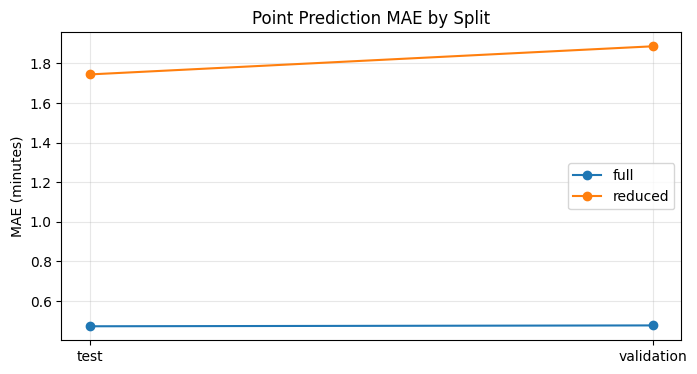

In [12]:
metrics_pd = spark.read.parquet(metrics_path).toPandas().sort_values(["model", "split"])
display(metrics_pd)

fig, ax = plt.subplots(figsize=(8, 4))
plot_pd = metrics_pd[metrics_pd["split"].isin(["validation", "test"])]
for model_name, group in plot_pd.groupby("model"):
    ax.plot(group["split"], group["mae"], marker="o", label=model_name)
ax.set_title("Point Prediction MAE by Split")
ax.set_ylabel("MAE (minutes)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


## Evaluation: Probability Calibration

We evaluate the confidence estimates on the test set. Since actual route-transfer slack is generated by the routing algorithm, we test several realistic slack values. For each event and slack value, we compute:

```text
predicted probability = P(residual <= slack - predicted_delay)
actual success = 1(actual_delay <= slack)
```

Then we bin predicted probabilities and compare them to observed success rates.

Using saved calibration outputs instead of recomputing.


LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/evaluation/calibration_scored_sample.parquet
LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/evaluation/calibration_summary.parquet


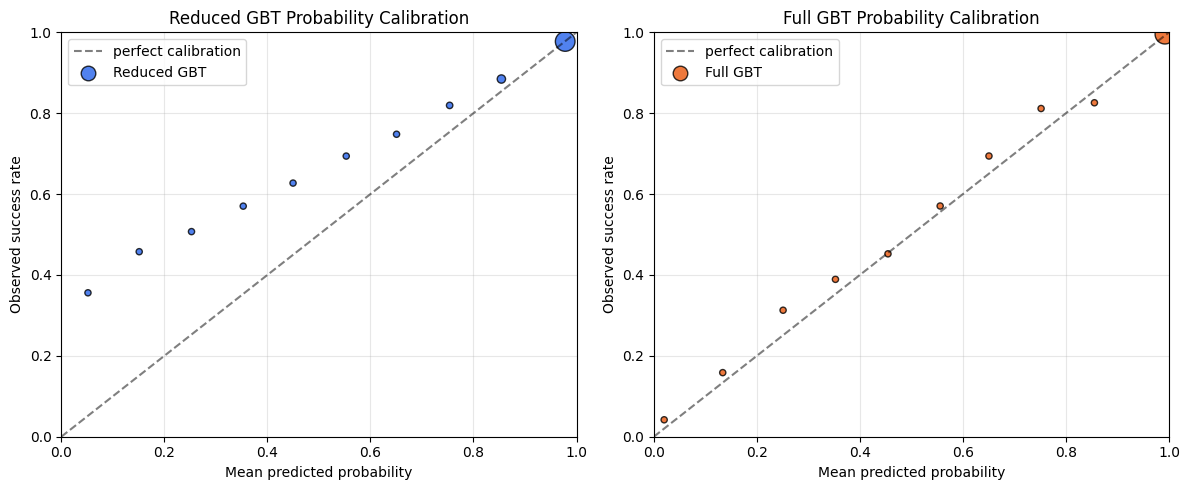

In [13]:
def build_calibration_events(test_pred_df: DataFrame, cfg: PipelineConfig) -> DataFrame:
    # Limit calibration size so the report cell remains manageable.
    base = test_pred_df.sample(fraction=cfg.calibration_sample_fraction, seed=cfg.seed).limit(cfg.calibration_max_rows)
    slack_df = spark.createDataFrame([(float(x),) for x in cfg.calibration_slack_minutes], ["usable_slack_min"])
    return (
        base.crossJoin(slack_df)
        .withColumn("actual_success", (F.col("arr_delay_min") <= F.col("usable_slack_min")).cast("double"))
    )




calibration_scored_path = f"{SAVE_BASE}/evaluation/calibration_scored_sample.parquet"
calibration_summary_path = f"{SAVE_BASE}/evaluation/calibration_summary.parquet"
if cfg.prefer_saved_artifacts and not cfg.rebuild_evaluation_outputs and hdfs_path_exists(calibration_scored_path) and hdfs_path_exists(calibration_summary_path):
    print("Using saved calibration outputs instead of recomputing.")
    calibration_scored_df = spark.read.parquet(calibration_scored_path)
    calibration_summary_df = spark.read.parquet(calibration_summary_path)
    print("LOADED:", calibration_scored_path)
    print("LOADED:", calibration_summary_path)
else:
    calibration_events_df = build_calibration_events(reduced_test_pred, cfg)
    calibration_scored_df = score_events_with_residual_lookup(calibration_events_df, residual_lookup_df)
    calibration_scored_df.write.mode("overwrite").parquet(calibration_scored_path)
    print("SAVED:", calibration_scored_path)

    calibration_summary_df = (
        calibration_scored_df
        .withColumn("prob_bin", F.floor(F.col("success_probability") * 10) / 10)
        .withColumn("prob_bin", F.when(F.col("prob_bin") >= 1.0, F.lit(0.9)).otherwise(F.col("prob_bin")))
        .groupBy("prob_bin")
        .agg(
            F.count("*").alias("n"),
            F.avg("success_probability").alias("mean_predicted_probability"),
            F.avg("actual_success").alias("observed_success_rate"),
            F.avg("usable_slack_min").alias("mean_slack_min"),
        )
        .orderBy("prob_bin")
    )
    calibration_summary_df.write.mode("overwrite").parquet(calibration_summary_path)
    print("SAVED:", calibration_summary_path)

reduced_calib_pd = calibration_summary_df.toPandas()

# Build local Global residual CDF for the Full GBT model using validation data
full_calib_events = build_calibration_events(full_test_pred, cfg)
full_val_residuals = full_validation_pred.select(
    (F.col("arr_delay_min") - F.col("prediction")).alias("res")
).dropna().select("res").rdd.flatMap(lambda x: x).collect()
full_val_residuals.sort()

def score_full_events_pandas(df_pd):
    df = df_pd.copy()
    margins = df["usable_slack_min"] - df["prediction"]
    probs = []
    for m in margins:
        idx = bisect.bisect_right(full_val_residuals, float(m))
        probs.append(float(idx) / len(full_val_residuals))
    df["success_probability"] = probs
    return df

full_calib_events_pd = full_calib_events.toPandas()
full_calib_scored_pd = score_full_events_pandas(full_calib_events_pd)

# Bin and summarize Full GBT
full_calib_scored_pd["prob_bin"] = (full_calib_scored_pd["success_probability"] * 10).astype(int) / 10.0
full_calib_scored_pd.loc[full_calib_scored_pd["prob_bin"] >= 1.0, "prob_bin"] = 0.9

full_calib_summary = full_calib_scored_pd.groupby("prob_bin").agg(
    n=("success_probability", "count"),
    mean_predicted_probability=("success_probability", "mean"),
    observed_success_rate=("actual_success", "mean")
).reset_index()

# Plot both curves side by side!
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="perfect calibration")
axes[0].scatter(
    reduced_calib_pd["mean_predicted_probability"], 
    reduced_calib_pd["observed_success_rate"], 
    s=np.maximum(20, reduced_calib_pd["n"] / max(reduced_calib_pd["n"].max(), 1) * 200),
    color="#2563eb",
    edgecolors="black",
    alpha=0.8,
    label="Reduced GBT"
)
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Observed success rate")
axes[0].set_title("Reduced GBT Probability Calibration")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="perfect calibration")
axes[1].scatter(
    full_calib_summary["mean_predicted_probability"], 
    full_calib_summary["observed_success_rate"], 
    s=np.maximum(20, full_calib_summary["n"] / max(full_calib_summary["n"].max(), 1) * 200),
    color="#ea580c",
    edgecolors="black",
    alpha=0.8,
    label="Full GBT"
)
axes[1].set_xlabel("Mean predicted probability")
axes[1].set_ylabel("Observed success rate")
axes[1].set_title("Full GBT Probability Calibration")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluation: Route-Level Sanity Check

This is a route-like sanity check using short historical trip slices. It is not the final routing evaluation, but it checks whether multiplying event probabilities behaves sensibly: higher requested confidence should accept fewer pseudo-routes.

Using saved route-level sanity output instead of recomputing.
LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/evaluation/route_sanity.parquet


26/05/29 07:39:44 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/05/29 07:39:44 WARN TaskSetManager: Stage 183 contains a task of very large size (12554 KiB). The maximum recommended task size is 1000 KiB.


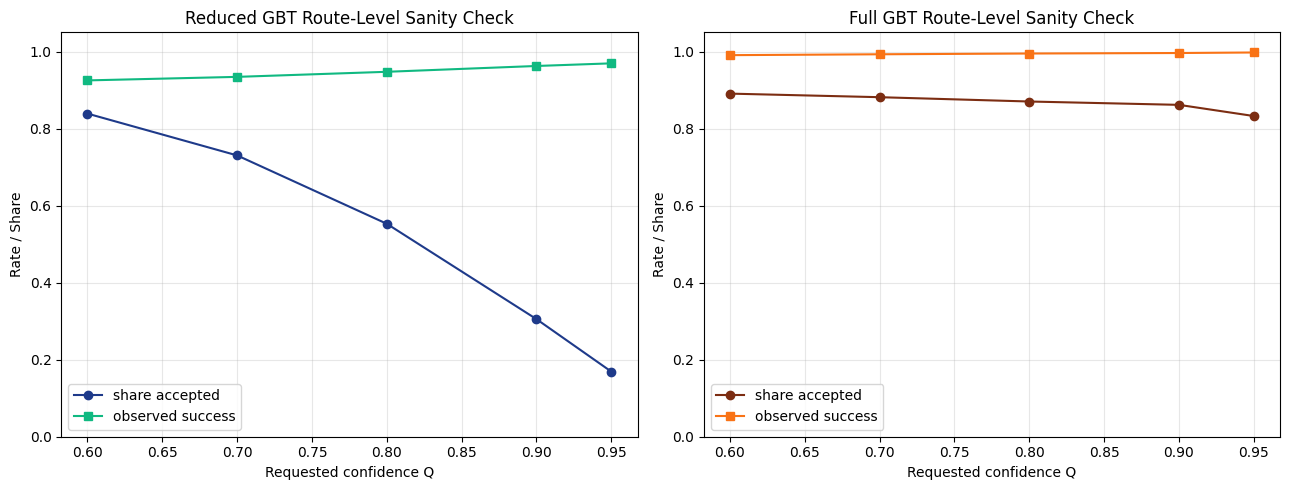

In [14]:
def route_level_sanity_check(scored_events_df: DataFrame, slack_min: float = 5.0, max_segments_per_trip: int = 3) -> DataFrame:
    filtered = scored_events_df.filter(F.col("usable_slack_min") == F.lit(float(slack_min)))
    w = Window.partitionBy("operating_day", "trip_id").orderBy("scheduled_arrival", "from_bpuic", "to_bpuic")
    pseudo = (
        filtered
        .withColumn("rn", F.row_number().over(w))
        .filter(F.col("rn") <= max_segments_per_trip)
        .groupBy("operating_day", "trip_id")
        .agg(
            F.count("*").alias("n_events"),
            F.exp(F.sum(F.log(F.greatest(F.col("success_probability"), F.lit(1e-9))))).alias("route_confidence"),
            F.min("actual_success").alias("route_success"),
            F.avg("prediction").alias("mean_predicted_delay_min"),
        )
        .filter(F.col("n_events") >= 2)
    )
    qs = spark.createDataFrame([(0.60,), (0.70,), (0.80,), (0.90,), (0.95,)], ["requested_confidence"])
    return (
        pseudo.crossJoin(qs)
        .withColumn("accepted", (F.col("route_confidence") >= F.col("requested_confidence")).cast("double"))
        .groupBy("requested_confidence")
        .agg(
            F.count("*").alias("n_pseudo_routes"),
            F.avg("accepted").alias("share_accepted"),
            F.avg(F.when(F.col("accepted") == 1, F.col("route_success"))).alias("observed_success_among_accepted"),
            F.avg(F.when(F.col("accepted") == 1, F.col("route_confidence"))).alias("mean_confidence_among_accepted"),
        )
        .orderBy("requested_confidence")
    )




route_sanity_path = f"{SAVE_BASE}/evaluation/route_sanity.parquet"
if cfg.prefer_saved_artifacts and not cfg.rebuild_evaluation_outputs and hdfs_path_exists(route_sanity_path):
    print("Using saved route-level sanity output instead of recomputing.")
    route_sanity_df = spark.read.parquet(route_sanity_path)
    print("LOADED:", route_sanity_path)
else:
    route_sanity_df = route_level_sanity_check(calibration_scored_df, slack_min=5.0, max_segments_per_trip=3)
    route_sanity_df.write.mode("overwrite").parquet(route_sanity_path)
    print("SAVED:", route_sanity_path)

reduced_sanity_pd = route_sanity_df.toPandas()

# Compute route-level sanity check for Full GBT model
full_calibration_scored_df = spark.createDataFrame(full_calib_scored_pd)
full_route_sanity_df = route_level_sanity_check(full_calibration_scored_df, slack_min=5.0, max_segments_per_trip=3)
full_sanity_pd = full_route_sanity_df.toPandas()

# Plot side-by-side!
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Reduced GBT
axes[0].plot(reduced_sanity_pd["requested_confidence"], reduced_sanity_pd["share_accepted"], marker="o", color="#1e3a8a", label="share accepted")
axes[0].plot(reduced_sanity_pd["requested_confidence"], reduced_sanity_pd["observed_success_among_accepted"], marker="s", color="#10b981", label="observed success")
axes[0].set_xlabel("Requested confidence Q")
axes[0].set_ylabel("Rate / Share")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Reduced GBT Route-Level Sanity Check")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Plot 2: Full GBT
axes[1].plot(full_sanity_pd["requested_confidence"], full_sanity_pd["share_accepted"], marker="o", color="#7c2d12", label="share accepted")
axes[1].plot(full_sanity_pd["requested_confidence"], full_sanity_pd["observed_success_among_accepted"], marker="s", color="#f97316", label="observed success")
axes[1].set_xlabel("Requested confidence Q")
axes[1].set_ylabel("Rate / Share")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Full GBT Route-Level Sanity Check")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## Qualitative Examples

We save a small set of examples for manual inspection: confident successes, confident failures, and low-confidence successes. These are useful for presentation and debugging.

In [15]:
examples_path = f"{SAVE_BASE}/evaluation/qualitative_examples.parquet"
if cfg.prefer_saved_artifacts and not cfg.rebuild_evaluation_outputs and hdfs_path_exists(examples_path):
    print("Using saved qualitative examples instead of recomputing.")
    examples_df = spark.read.parquet(examples_path)
    print("LOADED:", examples_path)
else:
    examples_df = (
        calibration_scored_df
        .withColumn(
            "case_type",
            F.when((F.col("success_probability") >= 0.85) & (F.col("actual_success") == 1), "high_conf_success")
            .when((F.col("success_probability") >= 0.85) & (F.col("actual_success") == 0), "high_conf_failure")
            .when((F.col("success_probability") <= 0.40) & (F.col("actual_success") == 1), "low_conf_success")
            .otherwise("other"),
        )
        .filter(F.col("case_type") != "other")
    )
    w = Window.partitionBy("case_type").orderBy(F.rand(cfg.seed))
    examples_df = examples_df.withColumn("rn", F.row_number().over(w)).filter(F.col("rn") <= 10).drop("rn")
    examples_df.write.mode("overwrite").parquet(examples_path)
    print("SAVED:", examples_path)

examples_df.select(
    "case_type", "from_bpuic", "to_bpuic", "line_text", "day_type", "time_bucket_15min",
    "usable_slack_min", "prediction", "arr_delay_min", "success_probability", "residual_level_used",
).show(50, truncate=False)


Using saved qualitative examples instead of recomputing.
LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/evaluation/qualitative_examples.parquet
+-----------------+----------+--------+---------+--------+-----------------+----------------+---------------------+--------------------+-------------------+----------------------+
|case_type        |from_bpuic|to_bpuic|line_text|day_type|time_bucket_15min|usable_slack_min|prediction           |arr_delay_min       |success_probability|residual_level_used   |
+-----------------+----------+--------+---------+--------+-----------------+----------------+---------------------+--------------------+-------------------+----------------------+
|high_conf_failure|8592116   |8592003 |1        |weekday |36               |12.0            |1.3300343005168214   |24.65               |1.0                |segment_daytype_bucket|
|high_conf_failure|8591988   |8592010 |18       |weekend |29               |3.0             |0.6875827161507387   |3.6

## Feature Importance

We aggregate raw GBDT feature importances back to feature groups. This makes the full-vs-reduced comparison easier to explain.

Using saved feature importance instead of recomputing.


LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/evaluation/feature_importance.parquet


,feature_group,importance,model
0,hist_segment_avg_delay,0.001869,reduced
1,scheduled_travel_time_min,0.001740,reduced
2,hour,0.001356,reduced
3,hist_operator_hour_avg_delay,0.015052,reduced
4,trip_progress,0.014839,reduced
5,time_bucket_15min,0.008594,reduced
6,n_segments_in_trip,0.112135,reduced
7,hist_line_hour_avg_delay,0.073344,reduced
8,hour_of_week,0.062953,reduced
9,how_cos,0.054158,reduced


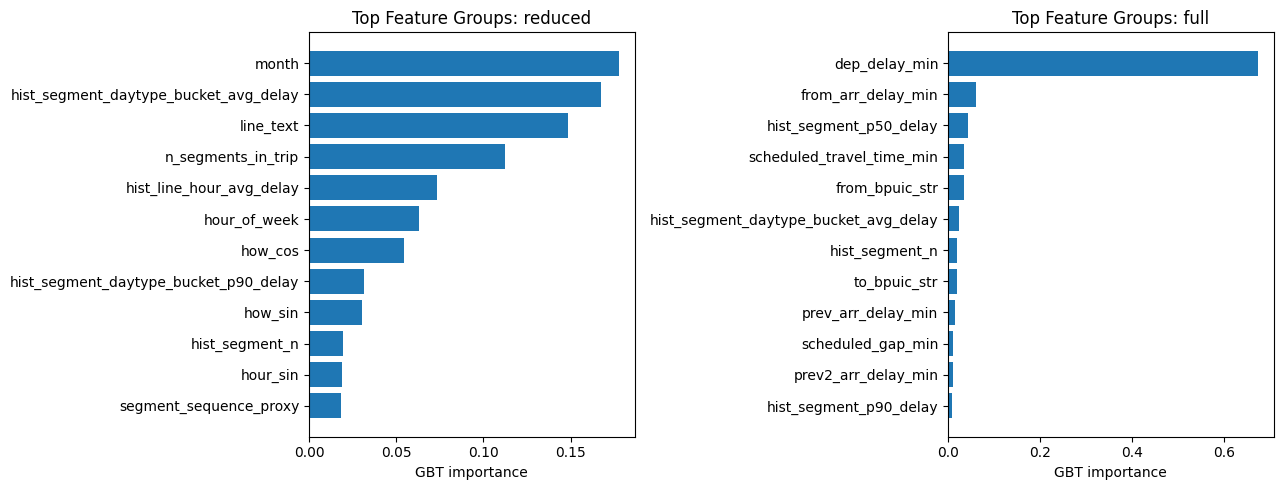

In [16]:
def feature_group_importance(fitted_model, transformed_sample_df: DataFrame, numeric_cols: List[str], cat_vec_cols: List[str]) -> pd.DataFrame:
    regressor = fitted_model.stages[-1]
    if not hasattr(regressor, "featureImportances"):
        return pd.DataFrame(columns=["feature_group", "importance"])

    importances = regressor.featureImportances.toArray()
    sample = transformed_sample_df.select(*cat_vec_cols).limit(1).collect()
    vec_sizes = {}
    if sample:
        row = sample[0]
        for c in cat_vec_cols:
            vec_sizes[c] = int(row[c].size)
    else:
        vec_sizes = {c: 1 for c in cat_vec_cols}

    groups = []
    pos = 0
    for c in numeric_cols:
        groups.append((c, float(importances[pos]) if pos < len(importances) else 0.0))
        pos += 1
    for c in cat_vec_cols:
        size = vec_sizes.get(c, 1)
        groups.append((c.replace("_vec", ""), float(importances[pos:pos + size].sum())))
        pos += size
    return pd.DataFrame(groups, columns=["feature_group", "importance"]).sort_values("importance", ascending=False)


importance_path = f"{SAVE_BASE}/evaluation/feature_importance.parquet"
if cfg.prefer_saved_artifacts and not cfg.rebuild_evaluation_outputs and hdfs_path_exists(importance_path):
    print("Using saved feature importance instead of recomputing.")
    importance_df = spark.read.parquet(importance_path)
    importance_pd = importance_df.toPandas()
    print("LOADED:", importance_path)
else:
    if test_df is None:
        print("Building test feature split for feature importance only.")
        test_df, _ = add_pretrip_history_features(test_base_df, train_base_df)
    reduced_importance_pd = feature_group_importance(reduced_model, reduced_model.transform(test_df.limit(1000)), reduced_numeric_cols, reduced_cat_vec_cols)
    full_importance_pd = feature_group_importance(full_model, full_model.transform(test_df.limit(1000)), full_numeric_cols, full_cat_vec_cols)

    importance_pd = pd.concat([
        reduced_importance_pd.assign(model="reduced"),
        full_importance_pd.assign(model="full"),
    ], ignore_index=True)
    spark.createDataFrame(importance_pd).write.mode("overwrite").parquet(importance_path)
    print("SAVED:", importance_path)

display(importance_pd.groupby("model").head(15))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, model_name, df in [(axes[0], "reduced", importance_pd[importance_pd["model"] == "reduced"].sort_values("importance", ascending=False).head(12)), (axes[1], "full", importance_pd[importance_pd["model"] == "full"].sort_values("importance", ascending=False).head(12))]:
    ax.barh(df["feature_group"][::-1], df["importance"][::-1])
    ax.set_title(f"Top Feature Groups: {model_name}")
    ax.set_xlabel("GBT importance")
plt.tight_layout()
plt.show()


## Artifacts Saved

Only key reusable artifacts are saved, all under `SAVE_BASE`:

- segment rows materialization
- reduced and full GBDT models
- validation/test predictions
- residual CDF lookup from validation residuals
- model metrics and evaluation summaries

The reduced model plus `residual_cdf_lookup_reduced.parquet` are the main routing-confidence artifacts.

In [17]:
artifact_manifest = {
    "save_base": SAVE_BASE,
    "segment_rows": segment_rows_path,
    "reduced_model": f"{SAVE_BASE}/models/reduced_gbt",
    "full_model": f"{SAVE_BASE}/models/full_gbt",
    "reduced_validation_predictions": f"{SAVE_BASE}/predictions/reduced_validation.parquet",
    "reduced_test_predictions": f"{SAVE_BASE}/predictions/reduced_test.parquet",
    "full_validation_predictions": f"{SAVE_BASE}/predictions/full_validation.parquet",
    "full_test_predictions": f"{SAVE_BASE}/predictions/full_test.parquet",
    "residual_cdf_lookup_reduced": residual_lookup_path,
    "model_metrics": metrics_path,
    "calibration_summary": calibration_summary_path,
    "route_sanity": route_sanity_path,
    "qualitative_examples": examples_path,
    "feature_importance": importance_path,
}
manifest_path = f"{SAVE_BASE}/artifact_manifest_json"
spark.createDataFrame([(json.dumps(artifact_manifest, indent=2),)], ["value"]).write.mode("overwrite").text(manifest_path)
print("SAVED:", manifest_path)
print(json.dumps(artifact_manifest, indent=2))


SAVED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/artifact_manifest_json
{
  "save_base": "/user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2",
  "segment_rows": "/user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/segment_rows.parquet",
  "reduced_model": "/user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/models/reduced_gbt",
  "full_model": "/user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/models/full_gbt",
  "reduced_validation_predictions": "/user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/predictions/reduced_validation.parquet",
  "reduced_test_predictions": "/user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/predictions/reduced_test.parquet",
  "full_validation_predictions": "/user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/predictions/full_validation.parquet",
  "full_test_predictions": "/user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/predictions/full_test.parquet",
  "residual_cdf_lookup_reduced": "/user/gro

## Part 4: End-to-End Route Planner Linkage

In this section, we connect our custom **Reverse Connection Scan Algorithm (CSA)** pathfinder (defined in `journey_planner.py`) with our PySpark Gradient Boosting models and out-of-sample residual CDF lookup tables.

### 4.1: Timetable Inputs, Event Extraction, & History Lookup Prep

We first define the helper functions to load stops and platform connections, convert generated candidate routes into individual **Transfer** and **Final Arrival** event rows, and prepare historical pre-trip delay lookups. 

We also integrate the newly developed `apply_recent_history_patch` function. This patch dynamically scans validation and test observations to adjust static delay profiles on active segments (e.g. the Flon-Ouchy metro family), capturing temporary regional delay shifts.

In [ ]:
from pyspark.ml import PipelineModel
from journey_planner import RobustJourneyPlanner

# Demo controls. Change these for the final presentation or route tests.
RUN_END_TO_END_DEMO = True
DEMO_START_STOP = "Ecublens VD, EPFL"
DEMO_END_STOP = "Lausanne, Ouchy-Olympique"
DEMO_CONFIDENCE_DESTINATIONS = [
    "Lausanne, Ouchy-Olympique",
    "Lausanne-Flon",
    "Lausanne, gare",
    "Renens VD, gare",
]
DEMO_DAY = "sunday"
DEMO_SERVICE_DATE = "2026-01-25"  # must match DEMO_DAY; used for month/weather/history features
DEMO_ARRIVAL_TIME = "15:00"
DEMO_REQUESTED_CONFIDENCE = 0.50
DEMO_MAX_WALK_M = 500  # assignment default; 2000m creates a very dense walk graph and slow queries
DEMO_MAX_ROUTES = 50
DEMO_MAX_LABELS_PER_STOP = 40
DEMO_MAX_TRANSIT_LEGS = 8
DEMO_MAX_SAME_TRIP_SKIP = 50  # keep full metro/train rides as one leg; lower values can create fake transfers
DEMO_MAX_WALK_NEIGHBORS = 12  # cap nearest walk edges per stop for query speed
DEMO_MAX_SEARCH_HOURS = 4  # city journeys should not need all-day backtracking
DEMO_CACHE_TAG = f"renens_croisettes_{DEMO_DAY}_1400_walk{int(DEMO_MAX_WALK_M)}_skip{DEMO_MAX_SAME_TRIP_SKIP}"
DEMO_CACHE_BASE = f"{SAVE_BASE}/demo_cache/{DEMO_CACHE_TAG}"


def normalize_mode_value(value: Any) -> str:
    value = "UNKNOWN" if pd.isna(value) else str(value).strip().upper()
    if value in {"", "?", "NULL", "NAN"}:
        return "UNKNOWN"
    if value in {"B", "BUS", "BUSS"}:
        return "BUS"
    if value in {"T", "TRAM"}:
        return "TRAM"
    if value in {"M", "METRO"}:
        return "METRO"
    if value in {"BAT", "BOAT", "SHIP", "SCHIFF"}:
        return "SHIP"
    if value in {"ZAHNRADBAHN", "CC"}:
        return "RACK_RAIL"
    return value


def haversine_m(lat1, lon1, lat2, lon2):
    radius_m = 6_371_000.0
    lat1 = math.radians(float(lat1))
    lon1 = math.radians(float(lon1))
    lat2 = math.radians(float(lat2))
    lon2 = math.radians(float(lon2))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    return 2 * radius_m * math.asin(math.sqrt(a))


def build_walk_edges_from_stops(stops_pd: pd.DataFrame, max_walk_m: float = 500.0) -> pd.DataFrame:
    cols = ["a_stop_id", "b_stop_id", "distance"]
    if stops_pd.empty:
        return pd.DataFrame(columns=cols)

    base = stops_pd.dropna(subset=["stop_lat", "stop_lon"]).drop_duplicates("stop_id").copy()
    # Build walking only for the region-sized stop set; this avoids an all-Switzerland O(n^2) join.
    rows = []
    values = base[["stop_id", "stop_lat", "stop_lon"]].to_records(index=False)
    for i in range(len(values)):
        stop_i, lat_i, lon_i = values[i]
        for j in range(i + 1, len(values)):
            stop_j, lat_j, lon_j = values[j]
            distance = haversine_m(lat_i, lon_i, lat_j, lon_j)
            if 0 < distance <= max_walk_m:
                rows.append((str(stop_i), str(stop_j), float(distance)))
    return pd.DataFrame(rows, columns=cols)


def load_planner_inputs_from_trino(conn, cfg: PipelineConfig, max_walk_m: float = 500.0, day: Optional[str] = None):
    day_filter = ""
    if day is not None:
        day_col = str(day).lower()
        if day_col not in {"monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"}:
            raise ValueError(f"Unknown day: {day}")
        day_filter = f" AND c.{day_col} = TRUE"
    region_table = f"{namespace}.region_stops_{cfg.region_name}"
    stop_times_sql = f"""
    WITH trips_touching_region AS (
        SELECT DISTINCT st.trip_id
        FROM {sharedNS}.sbb_stop_times st
        JOIN {region_table} rs
          ON st.stop_id = rs.stop_id
        WHERE st.pub_date = DATE '{cfg.timetable_date}'
    )
    SELECT
        st.trip_id,
        st.stop_id,
        st.stop_sequence,
        st.arrival_time,
        st.departure_time,
        c.monday, c.tuesday, c.wednesday, c.thursday, c.friday, c.saturday, c.sunday,
        COALESCE(CAST(r.agency_id AS varchar), 'UNKNOWN') AS operator_id,
        COALESCE(CAST(r.route_id AS varchar), CAST(t.route_id AS varchar), 'UNKNOWN') AS line_id,
        COALESCE(NULLIF(CAST(r.route_short_name AS varchar), ''), NULLIF(CAST(t.trip_short_name AS varchar), ''), 'UNKNOWN') AS line_text,
        COALESCE(NULLIF(CAST(r.route_desc AS varchar), ''), 'UNKNOWN') AS transport_clean,
        COALESCE(NULLIF(CAST(r.route_desc AS varchar), ''), 'UNKNOWN') AS product_id_clean
    FROM {sharedNS}.sbb_stop_times st
    JOIN trips_touching_region tr
      ON st.trip_id = tr.trip_id
    JOIN {sharedNS}.sbb_trips t
      ON st.pub_date = t.pub_date AND st.trip_id = t.trip_id
    JOIN {sharedNS}.sbb_calendar c
      ON t.pub_date = c.pub_date AND t.service_id = c.service_id
    LEFT JOIN {sharedNS}.sbb_routes r
      ON t.pub_date = r.pub_date AND t.route_id = r.route_id
    WHERE st.pub_date = DATE '{cfg.timetable_date}'
      {day_filter}
    ORDER BY st.trip_id, st.stop_sequence
    """
    stop_times_pd = pd.read_sql(stop_times_sql, conn)
    if stop_times_pd.empty:
        raise ValueError("No timetable rows found for the configured region/date.")

    stop_times_pd["stop_id"] = stop_times_pd["stop_id"].astype(str)
    for col in ["operator_id", "line_id", "line_text"]:
        stop_times_pd[col] = stop_times_pd[col].fillna("UNKNOWN").astype(str)
    for col in ["transport_clean", "product_id_clean"]:
        stop_times_pd[col] = stop_times_pd[col].apply(normalize_mode_value)
    for col in ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]:
        stop_times_pd[col] = stop_times_pd[col].astype(bool)

    stops_sql = f"""
    WITH route_stops AS (
        SELECT DISTINCT st.stop_id
        FROM {sharedNS}.sbb_stop_times st
        JOIN (
            SELECT DISTINCT st2.trip_id
            FROM {sharedNS}.sbb_stop_times st2
            JOIN {region_table} rs
              ON st2.stop_id = rs.stop_id
            WHERE st2.pub_date = DATE '{cfg.timetable_date}'
        ) tr ON st.trip_id = tr.trip_id
        WHERE st.pub_date = DATE '{cfg.timetable_date}'
    )
    SELECT s.stop_id, s.stop_name, s.stop_lat, s.stop_lon
    FROM {sharedNS}.sbb_stops s
    JOIN route_stops rs
      ON s.stop_id = rs.stop_id
    WHERE s.pub_date = DATE '{cfg.timetable_date}'
      AND NOT s.stop_id LIKE 'Parent%'
    """
    stops_pd = pd.read_sql(stops_sql, conn)
    stops_pd["stop_id"] = stops_pd["stop_id"].astype(str)

    region_stops_for_walk_pd = pd.read_sql(f"SELECT stop_id, stop_name, stop_lat, stop_lon FROM {region_table}", conn)
    # Walking needs the full timetable-expanded stop set too. Otherwise nearby destination
    # stops such as EPFL/Colladon can be visible on the map but unreachable by the router.
    walk_stop_pd = (
        pd.concat([stops_pd, region_stops_for_walk_pd], ignore_index=True)
        .drop_duplicates("stop_id")
    )
    walk_pd = build_walk_edges_from_stops(walk_stop_pd, max_walk_m=max_walk_m)
    print("Planner stops:", len(stops_pd), "stop_times:", len(stop_times_pd), "walk edges:", len(walk_pd))
    return stops_pd, walk_pd, stop_times_pd


def ensure_loaded_artifacts():
    global reduced_model, residual_lookup_df, segment_rows_df, train_base_df
    if "reduced_model" not in globals():
        reduced_model = PipelineModel.load(f"{SAVE_BASE}/models/reduced_gbt")
        print("LOADED:", f"{SAVE_BASE}/models/reduced_gbt")
    if "residual_lookup_df" not in globals():
        residual_lookup_df = spark.read.parquet(f"{SAVE_BASE}/residual_cdf_lookup_reduced.parquet")
        print("LOADED:", f"{SAVE_BASE}/residual_cdf_lookup_reduced.parquet")
    if "segment_rows_df" not in globals():
        segment_rows_df = spark.read.parquet(f"{SAVE_BASE}/segment_rows.parquet")
        print("LOADED:", f"{SAVE_BASE}/segment_rows.parquet")
    if "train_base_df" not in globals():
        train_base_df, _, _ = split_segment_rows(segment_rows_df, cfg)


In [22]:
def routes_to_event_rows(routes: Sequence[Mapping[str, Any]], service_date: str) -> pd.DataFrame:
    rows = []
    service_day = pd.Timestamp(service_date)
    for route_id, route in enumerate(routes):
        for event_id, event in enumerate(route.get("events_for_model", [])):
            row = dict(event)
            row["route_id"] = int(route_id)
            row["event_id"] = int(event_id)
            row["operating_day"] = service_day.date().isoformat()
            row["scheduled_arrival_ts"] = service_day + pd.to_timedelta(int(row["scheduled_arrival"]), unit="s")
            rows.append(row)
    return pd.DataFrame(rows)


def add_missing_columns(df: DataFrame, defaults: Mapping[str, Tuple[Any, str]]) -> DataFrame:
    """Spark cannot coalesce a missing column, so add stable defaults first."""
    for col_name, (default_value, dtype) in defaults.items():
        if col_name not in df.columns:
            df = df.withColumn(col_name, F.lit(default_value).cast(dtype))
    return df


def add_weather_to_route_events(events_df: DataFrame, weather_df: Optional[DataFrame]) -> DataFrame:
    if weather_df is None:
        return events_df
    weather_join_df = (
        weather_df
        .withColumnRenamed("weather_date", "weather_join_date")
        .withColumnRenamed("weather_hour", "weather_join_hour")
    )
    return (
        events_df
        .join(
            weather_join_df,
            (F.col("operating_day") == F.col("weather_join_date")) &
            (F.col("hour") == F.col("weather_join_hour")),
            "left",
        )
        .drop("weather_join_date", "weather_join_hour")
    )


HISTORY_FEATURE_BASE = f"{SAVE_BASE}/feature_history_reduced"
HISTORY_LOOKUP_PATHS = {
    "defaults": f"{HISTORY_FEATURE_BASE}/defaults.parquet",
    "segment_hist": f"{HISTORY_FEATURE_BASE}/segment_hist.parquet",
    "segment_daytype_bucket_hist": f"{HISTORY_FEATURE_BASE}/segment_daytype_bucket_hist.parquet",
    "to_stop_daytype_bucket_hist": f"{HISTORY_FEATURE_BASE}/to_stop_daytype_bucket_hist.parquet",
    "operator_hour_hist": f"{HISTORY_FEATURE_BASE}/operator_hour_hist.parquet",
    "line_hour_hist": f"{HISTORY_FEATURE_BASE}/line_hour_hist.parquet",
}
_PRETRIP_HISTORY_CACHE = {}


def build_pretrip_history_lookup_tables(reference_train_df: DataFrame) -> None:
    """Build once, then reuse for every interactive route query."""
    print("Building one-time pretrip history lookup tables for demo scoring...")
    global_row = reference_train_df.agg(
        F.avg("arr_delay_min").alias("global_avg_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.50, 200)").alias("global_p50_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.90, 200)").alias("global_p90_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.95, 200)").alias("global_p95_delay"),
    ).first()
    defaults = {k: float(global_row[k] or 0.0) for k in global_row.asDict()}
    spark.createDataFrame([defaults]).write.mode("overwrite").parquet(HISTORY_LOOKUP_PATHS["defaults"])

    reference_train_df.groupBy("from_bpuic", "to_bpuic").agg(
        F.count("*").alias("hist_segment_n"),
        F.avg("arr_delay_min").alias("hist_segment_avg_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.50, 200)").alias("hist_segment_p50_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.90, 200)").alias("hist_segment_p90_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.95, 200)").alias("hist_segment_p95_delay"),
    ).write.mode("overwrite").parquet(HISTORY_LOOKUP_PATHS["segment_hist"])

    reference_train_df.groupBy("from_bpuic", "to_bpuic", "day_type", "time_bucket_15min").agg(
        F.avg("arr_delay_min").alias("hist_segment_daytype_bucket_avg_delay"),
        F.expr("percentile_approx(arr_delay_min, 0.90, 200)").alias("hist_segment_daytype_bucket_p90_delay"),
    ).write.mode("overwrite").parquet(HISTORY_LOOKUP_PATHS["segment_daytype_bucket_hist"])

    reference_train_df.groupBy("to_bpuic", "day_type", "time_bucket_15min").agg(
        F.avg("arr_delay_min").alias("hist_to_stop_daytype_bucket_avg_delay"),
    ).write.mode("overwrite").parquet(HISTORY_LOOKUP_PATHS["to_stop_daytype_bucket_hist"])

    reference_train_df.groupBy("operator_id", "hour").agg(
        F.avg("arr_delay_min").alias("hist_operator_hour_avg_delay"),
    ).write.mode("overwrite").parquet(HISTORY_LOOKUP_PATHS["operator_hour_hist"])

    reference_train_df.groupBy("line_text", "hour").agg(
        F.avg("arr_delay_min").alias("hist_line_hour_avg_delay"),
    ).write.mode("overwrite").parquet(HISTORY_LOOKUP_PATHS["line_hour_hist"])

    for path in HISTORY_LOOKUP_PATHS.values():
        print("SAVED:", path)


def ensure_pretrip_history_lookup_tables() -> Tuple[Dict[str, DataFrame], Dict[str, float]]:
    global _PRETRIP_HISTORY_CACHE
    if _PRETRIP_HISTORY_CACHE:
        return _PRETRIP_HISTORY_CACHE["tables"], _PRETRIP_HISTORY_CACHE["defaults"]

    missing = [path for path in HISTORY_LOOKUP_PATHS.values() if not hdfs_path_exists(path)]
    if missing:
        ensure_loaded_artifacts()
        build_pretrip_history_lookup_tables(train_base_df)

    defaults = {k: float(v or 0.0) for k, v in spark.read.parquet(HISTORY_LOOKUP_PATHS["defaults"]).first().asDict().items()}
    tables = {
        name: spark.read.parquet(path)
        for name, path in HISTORY_LOOKUP_PATHS.items()
        if name != "defaults"
    }
    _PRETRIP_HISTORY_CACHE = {"tables": tables, "defaults": defaults}
    print("LOADED pretrip history lookup tables from:", HISTORY_FEATURE_BASE)
    return tables, defaults


def add_pretrip_history_features_from_lookup(target_df: DataFrame) -> DataFrame:
    tables, defaults = ensure_pretrip_history_lookup_tables()
    return (
        target_df
        .join(tables["segment_hist"], on=["from_bpuic", "to_bpuic"], how="left")
        .join(tables["segment_daytype_bucket_hist"], on=["from_bpuic", "to_bpuic", "day_type", "time_bucket_15min"], how="left")
        .join(tables["to_stop_daytype_bucket_hist"], on=["to_bpuic", "day_type", "time_bucket_15min"], how="left")
        .join(tables["operator_hour_hist"], on=["operator_id", "hour"], how="left")
        .join(tables["line_hour_hist"], on=["line_text", "hour"], how="left")
        .fillna({
            "hist_segment_n": 0,
            "hist_segment_avg_delay": defaults["global_avg_delay"],
            "hist_segment_p50_delay": defaults["global_p50_delay"],
            "hist_segment_p90_delay": defaults["global_p90_delay"],
            "hist_segment_p95_delay": defaults["global_p95_delay"],
            "hist_segment_daytype_bucket_avg_delay": defaults["global_avg_delay"],
            "hist_segment_daytype_bucket_p90_delay": defaults["global_p90_delay"],
            "hist_to_stop_daytype_bucket_avg_delay": defaults["global_avg_delay"],
            "hist_operator_hour_avg_delay": defaults["global_avg_delay"],
            "hist_line_hour_avg_delay": defaults["global_avg_delay"],
        })
    )


def prepare_route_events_for_reduced_model(events_pd: pd.DataFrame) -> DataFrame:
    """
    Convert route-planner events into the same feature columns used by the reduced model.

    This function is deliberately tolerant: if the cluster has an older journey_planner.py
    that does not emit operator/line/mode fields, it fills them with UNKNOWN instead of
    failing. The reduced model can still score the route, but the prediction is better
    when the updated planner metadata is available.
    """
    if events_pd.empty:
        raise ValueError("No route events to score.")

    events_df = spark.createDataFrame(events_pd)
    events_df = add_missing_columns(events_df, {
        "operator_id": ("UNKNOWN", "string"),
        "line_id": ("UNKNOWN", "string"),
        "line_text": ("UNKNOWN", "string"),
        "transport_clean": ("UNKNOWN", "string"),
        "product_id_clean": ("UNKNOWN", "string"),
        "scheduled_travel_time_min": (0.0, "double"),
        "segment_sequence_proxy": (1, "int"),
        "n_segments_in_trip": (1, "int"),
        "trip_progress": (1.0, "double"),
        "hour": (0, "int"),
        "day_of_week": (2, "int"),
        "time_bucket_15min": (0, "int"),
        "hour_of_week": (24, "int"),
        "day_type": ("weekday", "string"),
    })

    events_df = (
        events_df
        .withColumn("operating_day", F.to_date("operating_day"))
        .withColumn("scheduled_arrival_ts", F.to_timestamp("scheduled_arrival_ts"))
        .withColumn("from_bpuic", F.col("from_bpuic").cast("int"))
        .withColumn("to_bpuic", F.col("to_bpuic").cast("int"))
        .withColumn("from_bpuic_str", F.col("from_bpuic").cast("string"))
        .withColumn("to_bpuic_str", F.col("to_bpuic").cast("string"))
        .withColumn("operator_id", F.coalesce(F.col("operator_id"), F.lit("UNKNOWN")).cast("string"))
        .withColumn("line_text", F.coalesce(F.col("line_text"), F.lit("UNKNOWN")).cast("string"))
        .withColumn("transport_clean", F.coalesce(F.col("transport_clean"), F.lit("UNKNOWN")).cast("string"))
        .withColumn("product_id_clean", F.coalesce(F.col("product_id_clean"), F.lit("UNKNOWN")).cast("string"))
        .withColumn("month", F.month("operating_day"))
        .withColumn("is_weekend", F.col("day_of_week").isin([1, 7]).cast("int"))
        .withColumn("hour_sin", F.sin(2 * F.pi() * F.col("hour") / F.lit(24.0)))
        .withColumn("hour_cos", F.cos(2 * F.pi() * F.col("hour") / F.lit(24.0)))
        .withColumn("how_sin", F.sin(2 * F.pi() * F.col("hour_of_week") / F.lit(168.0)))
        .withColumn("how_cos", F.cos(2 * F.pi() * F.col("hour_of_week") / F.lit(168.0)))
        .withColumn("scheduled_gap_min", F.lit(0.0))
        .withColumn("scheduled_headway_min", F.lit(180.0))
    )

    events_df = add_weather_to_route_events(events_df, weather_df)
    for col_name in ["temperature_2m", "rain_mm", "precipitation_mm", "snowfall_cm", "precipitation_past_3h", "is_daylight"]:
        if col_name not in events_df.columns:
            events_df = events_df.withColumn(col_name, F.lit(0.0))

    events_df = events_df.fillna({
        "temperature_2m": 0.0,
        "rain_mm": 0.0,
        "precipitation_mm": 0.0,
        "snowfall_cm": 0.0,
        "precipitation_past_3h": 0.0,
        "is_daylight": 0,
        "scheduled_travel_time_min": 0.0,
        "segment_sequence_proxy": 1,
        "n_segments_in_trip": 1,
        "trip_progress": 1.0,
    })

    return add_pretrip_history_features_from_lookup(events_df)

def apply_recent_history_patch(
    model_events_df: DataFrame,
    history_df: DataFrame,
    service_date: str,
    lookback_days: int = 180,
    min_recent_bucket_n: int = 20,
    min_recent_segment_n: int = 50,
    min_recent_seq_n: int = 10,
) -> DataFrame:
    """
    Patch route-event model features using recent history before prediction.

    Why:
    The static train_base_df historical aggregates can be stale. For example,
    the M2 Flon -> Ouchy bucket had pessimistic early-2025 aggregates, which
    pushed prediction from about 2.2-2.4 min to 3.5 min.

    This function updates:
      - segment + day_type + 15min bucket delay features
      - broader segment delay features
      - sequence/progress fields using dominant recent historical shape
    """

    history_recent_df = (
        history_df
        .withColumn("operating_day", F.to_date("operating_day"))
        .filter(F.col("operating_day") < F.to_date(F.lit(service_date)))
        .filter(F.col("operating_day") >= F.date_sub(F.to_date(F.lit(service_date)), lookback_days))
    )

    recent_segment_bucket_df = (
        history_recent_df
        .groupBy("from_bpuic", "to_bpuic", "day_type", "time_bucket_15min")
        .agg(
            F.count("*").alias("recent_segment_bucket_n"),
            F.avg("arr_delay_min").alias("recent_segment_bucket_avg_delay"),
            F.expr("percentile_approx(arr_delay_min, 0.50, 200)").alias("recent_segment_bucket_p50_delay"),
            F.expr("percentile_approx(arr_delay_min, 0.90, 200)").alias("recent_segment_bucket_p90_delay"),
            F.expr("percentile_approx(arr_delay_min, 0.95, 200)").alias("recent_segment_bucket_p95_delay"),
        )
    )

    recent_segment_df = (
        history_recent_df
        .groupBy("from_bpuic", "to_bpuic")
        .agg(
            F.count("*").alias("recent_segment_n"),
            F.avg("arr_delay_min").alias("recent_segment_avg_delay"),
            F.expr("percentile_approx(arr_delay_min, 0.50, 200)").alias("recent_segment_p50_delay"),
            F.expr("percentile_approx(arr_delay_min, 0.90, 200)").alias("recent_segment_p90_delay"),
            F.expr("percentile_approx(arr_delay_min, 0.95, 200)").alias("recent_segment_p95_delay"),
        )
    )

    seq_counts_df = (
        history_recent_df
        .groupBy(
            "from_bpuic",
            "to_bpuic",
            "day_type",
            "hour",
            "segment_sequence_proxy",
            "n_segments_in_trip",
        )
        .agg(F.count("*").alias("recent_seq_count"))
    )

    w = Window.partitionBy(
        "from_bpuic", "to_bpuic", "day_type", "hour"
    ).orderBy(F.desc("recent_seq_count"))

    dominant_seq_df = (
        seq_counts_df
        .withColumn("rn", F.row_number().over(w))
        .filter(F.col("rn") == 1)
        .drop("rn")
        .withColumnRenamed("segment_sequence_proxy", "recent_segment_sequence_proxy")
        .withColumnRenamed("n_segments_in_trip", "recent_n_segments_in_trip")
    )

    patched_df = (
        model_events_df
        .join(
            recent_segment_bucket_df,
            ["from_bpuic", "to_bpuic", "day_type", "time_bucket_15min"],
            "left",
        )
        .join(
            recent_segment_df,
            ["from_bpuic", "to_bpuic"],
            "left",
        )
        .join(
            dominant_seq_df,
            ["from_bpuic", "to_bpuic", "day_type", "hour"],
            "left",
        )
    )

    patched_df = (
        patched_df

        # Specific segment + day type + 15-minute bucket.
        .withColumn(
            "hist_segment_daytype_bucket_avg_delay",
            F.when(
                F.col("recent_segment_bucket_n") >= min_recent_bucket_n,
                F.col("recent_segment_bucket_avg_delay"),
            ).otherwise(F.col("hist_segment_daytype_bucket_avg_delay"))
        )
        .withColumn(
            "hist_segment_daytype_bucket_p90_delay",
            F.when(
                F.col("recent_segment_bucket_n") >= min_recent_bucket_n,
                F.col("recent_segment_bucket_p90_delay"),
            ).otherwise(F.col("hist_segment_daytype_bucket_p90_delay"))
        )

        # Broader segment history.
        .withColumn(
            "hist_segment_avg_delay",
            F.when(
                F.col("recent_segment_n") >= min_recent_segment_n,
                F.col("recent_segment_avg_delay"),
            ).otherwise(F.col("hist_segment_avg_delay"))
        )
        .withColumn(
            "hist_segment_p50_delay",
            F.when(
                F.col("recent_segment_n") >= min_recent_segment_n,
                F.col("recent_segment_p50_delay"),
            ).otherwise(F.col("hist_segment_p50_delay"))
        )
        .withColumn(
            "hist_segment_p90_delay",
            F.when(
                F.col("recent_segment_n") >= min_recent_segment_n,
                F.col("recent_segment_p90_delay"),
            ).otherwise(F.col("hist_segment_p90_delay"))
        )
        .withColumn(
            "hist_segment_p95_delay",
            F.when(
                F.col("recent_segment_n") >= min_recent_segment_n,
                F.col("recent_segment_p95_delay"),
            ).otherwise(F.col("hist_segment_p95_delay"))
        )

        # Sequence/progress correction.
        .withColumn(
            "segment_sequence_proxy",
            F.when(
                F.col("recent_seq_count") >= min_recent_seq_n,
                F.col("recent_segment_sequence_proxy"),
            ).otherwise(F.col("segment_sequence_proxy"))
        )
        .withColumn(
            "n_segments_in_trip",
            F.when(
                F.col("recent_seq_count") >= min_recent_seq_n,
                F.col("recent_n_segments_in_trip"),
            ).otherwise(F.col("n_segments_in_trip"))
        )
        .withColumn(
            "trip_progress",
            F.when(
                (F.col("recent_seq_count") >= min_recent_seq_n)
                & (F.col("recent_n_segments_in_trip") > 0),
                F.col("recent_segment_sequence_proxy") / F.col("recent_n_segments_in_trip"),
            ).otherwise(F.col("trip_progress"))
        )
    )

    return patched_df



### 4.2: Route Recomposition & Display Deduplication

Once the planner generates raw, timetable-feasible candidate routes, we must reconstruct the passenger-facing steps, remove redundant variants (such as walking options that differ by only a few meters), and calculate the joint probability of making every connection.


In [23]:
def route_display_signature(route: Mapping[str, Any], planner: RobustJourneyPlanner) -> Tuple:
    """
    Signature for display-level deduplication.

    We keep routes with different transit structure, but remove variants that
    only differ by tiny internal walking/platform movements.

    Example:
        Same bus + same second bus + different final Ouchy platform walk
        -> considered the same route for display.
    """
    signature = []

    for step in route.get("steps", []):
        if step.get("type") != "TRANSIT":
            continue

        signature.append(
            (
                str(step.get("trip_id")),
                planner._name(step.get("from")),
                planner._name(step.get("to")),
            )
        )

    return tuple(signature)


def deduplicate_routes_for_display(
    routes: Sequence[Mapping[str, Any]],
    planner: RobustJourneyPlanner,
) -> List[Dict[str, Any]]:
    """
    Remove duplicate display routes while preserving teacher-required order:
    latest departure first, then confidence, then fewer transfers/walking.
    """
    sorted_routes = sorted(
        routes,
        key=lambda r: (
            -int(r.get("departure_seconds", 0)),      # teacher requirement
            -float(r.get("confidence", 0.0)),         # keep best variant
            int(r.get("transit_legs", 999)),
            float(r.get("walk_m", 0.0)),
        ),
    )

    deduped = []
    seen = set()

    for route in sorted_routes:
        sig = route_display_signature(route, planner)

        # If there are no transit legs, fall back to stop sequence.
        if not sig:
            sig = tuple(
                (step.get("type"), planner._name(step.get("from")), planner._name(step.get("to")))
                for step in route.get("steps", [])
            )

        if sig in seen:
            continue

        seen.add(sig)
        deduped.append(dict(route))

    return deduped


def attach_scored_events_to_routes(routes: Sequence[Mapping[str, Any]], scored_events_df: DataFrame, min_confidence: float) -> Tuple[List[Dict[str, Any]], pd.DataFrame]:
    event_cols = [
        "route_id", "event_id", "event_type", "from_bpuic", "to_bpuic", "scheduled_arrival",
        "day_type", "time_bucket_15min", "hour_of_week", "day_of_week",
        "usable_slack_min", "prediction", "margin_min", "success_probability", "residual_level_used",
        "n_obs_0", "n_obs_1", "n_obs_2", "n_obs_3", "n_obs_4", "n_obs_5", "n_obs_6",
    ]
    event_scores_pd = scored_events_df.select(*[c for c in event_cols if c in scored_events_df.columns]).toPandas()
    scored_routes = []
    for route_id, route in enumerate(routes):
        event_scores = event_scores_pd[event_scores_pd["route_id"] == route_id].sort_values("event_id")
        confidence = float(event_scores["success_probability"].prod()) if len(event_scores) else 1.0
        new_route = dict(route)
        new_route["confidence"] = confidence
        new_route["probability_events"] = event_scores.to_dict("records")
        if confidence >= min_confidence:
            scored_routes.append(new_route)
    # Final route order required by the assignment:
    # latest departure first. Duplicates are removed later once we have the planner.
    scored_routes = sorted(
        scored_routes,
        key=lambda r: (
            -int(r.get("departure_seconds", 0)),
            -float(r.get("confidence", 0.0)),
            int(r.get("transit_legs", 999)),
            float(r.get("walk_m", 0.0)),
        ),
    )
    
    return scored_routes, event_scores_pd


_PLANNER_CACHE = {}




### 4.3: End-to-End Robust Planning Engine

We now define `plan_robust_journey`, the primary routing driver of our system. It runs the **Reverse CSA** engine to find candidate paths, extracts transit events, patches features using recent history, predicts delays with the GBT model, lookup segments using validation residual CDFs, and returns routes that satisfy the passenger's $Q\%$ confidence threshold.


In [24]:
def get_planner_for_day(day: str, max_walk_m: float, max_same_trip_skip: int, max_walk_neighbors: int) -> Tuple[RobustJourneyPlanner, pd.DataFrame]:
    cache_key = (str(day).lower(), float(max_walk_m), int(max_same_trip_skip), int(max_walk_neighbors), cfg.timetable_date, tuple(cfg.region_uuids))
    if cache_key in _PLANNER_CACHE:
        return _PLANNER_CACHE[cache_key]

    stops_pd, walk_pd, stop_times_pd = load_planner_inputs_from_trino(conn, cfg, max_walk_m=max_walk_m, day=day)
    planner = RobustJourneyPlanner()
    planner.prepare(
        stops_pd,
        walk_pd,
        stop_times_pd,
        max_same_trip_skip=max_same_trip_skip,
        max_walk_neighbors=max_walk_neighbors,
    )
    _PLANNER_CACHE[cache_key] = (planner, stops_pd)
    return planner, stops_pd


def plan_robust_journey(
    *,
    start_stop: str,
    end_stop: str,
    arrival_time: str,
    day: str,
    service_date: str,
    requested_confidence: float = 0.80,
    max_walk_m: float = 500.0,
    max_routes: int = 10,
    max_transit_legs: int = 12,
    max_same_trip_skip: int = 8,
    max_walk_neighbors: int = 12,
    max_labels_per_stop: int = 40,
    max_search_seconds: int = 4 * 3600,
    use_recent_history_patch: bool = True,
    recent_history_lookback_days: int = 180,
) -> Tuple[List[Dict[str, Any]], pd.DataFrame, pd.DataFrame, RobustJourneyPlanner, pd.DataFrame]:
    """
    End-to-end robust planner used by the project demo.

    Returns:
        scored_routes: route dictionaries with confidence and per-event probabilities
        route_summary_pd: compact table for display
        event_scores_pd: per-transfer/final-arrival probabilities
        planner: fitted RobustJourneyPlanner object for printing routes
        stops_pd: stop coordinates for visualization
    """
    ensure_loaded_artifacts()
    planner, stops_pd = get_planner_for_day(
        day,
        max_walk_m=max_walk_m,
        max_same_trip_skip=max_same_trip_skip,
        max_walk_neighbors=max_walk_neighbors,
    )

    candidate_routes = planner.route_reverse(
        start_stop,
        end_stop,
        arrival_time=arrival_time,
        day=day,
        max_walk_m=max_walk_m,
        max_routes=max_routes,
        max_labels_per_stop=max_labels_per_stop,
        max_transit_legs=max_transit_legs,
        min_transfer_seconds=cfg.min_transfer_seconds,
        max_search_seconds=max_search_seconds,
    )
    print("Candidate routes:", len(candidate_routes))

    if not candidate_routes:
        empty_summary = pd.DataFrame(columns=["rank", "departure_time", "arrival_deadline", "confidence", "transit_legs", "walk_m"])
        empty_events = pd.DataFrame()
        return [], empty_summary, empty_events, planner, stops_pd

    route_events_pd = routes_to_event_rows(candidate_routes, service_date)
    if route_events_pd.empty:
        # Pure walking routes have no transit-delay event to score.
        scored_routes = []
        for route in candidate_routes:
            route = dict(route)
            route["confidence"] = 1.0
            route["probability_events"] = []
            if route["confidence"] >= requested_confidence:
                scored_routes.append(route)
        event_scores_pd = pd.DataFrame()
    else:
        model_events_df = prepare_route_events_for_reduced_model(route_events_pd)
        print("Using recent history patch:", use_recent_history_patch)
        if use_recent_history_patch:
            model_events_df = apply_recent_history_patch(
                model_events_df=model_events_df,
                history_df=recent_history_df,
                service_date=service_date,
                lookback_days=recent_history_lookback_days,
            )
    
        predicted_events_df = reduced_model.transform(model_events_df)
        scored_events_df = score_events_with_residual_lookup(predicted_events_df, residual_lookup_df).cache()
        scored_routes, event_scores_pd = attach_scored_events_to_routes(candidate_routes, scored_events_df, requested_confidence)
        scored_events_df.unpersist()
    print("Routes passing confidence threshold:", len(scored_routes))
    before_dedup = len(scored_routes)
    scored_routes = deduplicate_routes_for_display(scored_routes, planner)
    print("Routes after display deduplication:", len(scored_routes), f"(removed {before_dedup - len(scored_routes)})")

    route_summary_pd = pd.DataFrame([
        {
            "rank": i + 1,
            "departure_time": r["departure_time"],
            "arrival_deadline": r["arrival_deadline"],
            "confidence": r["confidence"],
            "transit_legs": r["transit_legs"],
            "walk_m": r["walk_m"],
        }
        for i, r in enumerate(scored_routes)
    ])
    return scored_routes, route_summary_pd, event_scores_pd, planner, stops_pd




### 4.4: Diagnostic Visualizations & Probability Distribution Curves

To help users inspect their routes, we define plotting functions to color-code confidence levels, resolve partial stop names into SBB stop IDs, and visualize individual transfer segment probability distributions.


In [25]:
def confidence_color(confidence: float) -> str:
    if pd.isna(confidence):
        return "#9ca3af"
    confidence = float(confidence)
    if confidence >= 0.90:
        return "#15803d"
    if confidence >= 0.80:
        return "#65a30d"
    if confidence >= 0.65:
        return "#ca8a04"
    if confidence >= 0.50:
        return "#ea580c"
    return "#dc2626"


def resolve_stop_row(stops_pd: pd.DataFrame, stop: str) -> Optional[pd.Series]:
    if stops_pd.empty or stop is None:
        return None
    stop = str(stop)
    exact_id = stops_pd[stops_pd["stop_id"].astype(str) == stop]
    if len(exact_id):
        return exact_id.iloc[0]
    exact_name = stops_pd[stops_pd["stop_name"].astype(str).str.lower() == stop.lower()]
    if len(exact_name):
        return exact_name.iloc[0]
    partial_name = stops_pd[stops_pd["stop_name"].astype(str).str.lower().str.contains(stop.lower(), na=False)]
    if len(partial_name):
        return partial_name.iloc[0]
    return None


def plot_confidence_distribution_map(
    confidence_pd: pd.DataFrame,
    stops_pd: pd.DataFrame,
    origin_stop: Optional[str] = None,
    selected_route: Optional[Mapping[str, Any]] = None,
    title: str = "Route Confidence Distribution",
):
    import folium

    stops = stops_pd.drop_duplicates("stop_id").copy()
    stops["stop_id"] = stops["stop_id"].astype(str)
    confidence = confidence_pd.copy()
    if "stop_id" in confidence.columns:
        confidence["stop_id"] = confidence["stop_id"].astype(str)
        map_pd = confidence.merge(stops, on="stop_id", how="left", suffixes=("", "_stop"))
    elif "stop_name" in confidence.columns:
        map_pd = confidence.merge(stops, on="stop_name", how="left", suffixes=("", "_stop"))
    else:
        raise ValueError("confidence_pd must contain either stop_id or stop_name.")

    map_pd = map_pd.dropna(subset=["stop_lat", "stop_lon"])
    if map_pd.empty:
        raise ValueError("No confidence rows could be matched to stop coordinates.")

    fmap = folium.Map(
        location=[float(map_pd["stop_lat"].mean()), float(map_pd["stop_lon"].mean())],
        zoom_start=12,
        tiles="cartodbpositron",
    )

    origin_row = resolve_stop_row(stops, origin_stop) if origin_stop is not None else None
    if origin_row is not None:
        folium.Marker(
            [float(origin_row["stop_lat"]), float(origin_row["stop_lon"])],
            popup=f"Origin: {origin_row['stop_name']}",
            tooltip=f"Origin: {origin_row['stop_name']}",
            icon=folium.Icon(color="blue", icon="play"),
        ).add_to(fmap)

    for _, row in map_pd.iterrows():
        conf = float(row["confidence"]) if not pd.isna(row["confidence"]) else 0.0
        color = confidence_color(conf)
        stop_name = row.get("stop_name", row.get("stop_id", "unknown stop"))
        details = [f"<b>{stop_name}</b>", f"Confidence: {conf:.3f}"]
        for label, col in [("Departure", "best_departure_time"), ("Transit legs", "transit_legs"), ("Walk m", "walk_m")]:
            if col in row and not pd.isna(row[col]):
                details.append(f"{label}: {row[col]}")
        folium.CircleMarker(
            location=[float(row["stop_lat"]), float(row["stop_lon"])],
            radius=7 + 10 * max(0.0, min(1.0, conf)),
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.75,
            weight=2,
            popup=folium.Popup("<br>".join(details), max_width=260),
            tooltip=f"{stop_name}: {conf:.3f}",
        ).add_to(fmap)

    if selected_route:
        stop_lookup = stops.set_index("stop_id")
        for step in selected_route.get("steps", []):
            from_id = str(step["from"])
            to_id = str(step["to"])
            if from_id not in stop_lookup.index or to_id not in stop_lookup.index:
                continue
            a = stop_lookup.loc[from_id]
            b = stop_lookup.loc[to_id]
            folium.PolyLine(
                [[float(a["stop_lat"]), float(a["stop_lon"])], [float(b["stop_lat"]), float(b["stop_lon"])]],
                color="#2563eb" if step.get("type") == "TRANSIT" else "#64748b",
                weight=5 if step.get("type") == "TRANSIT" else 3,
                opacity=0.75,
                dash_array=None if step.get("type") == "TRANSIT" else "5, 8",
            ).add_to(fmap)

    legend_html = f"""
    <div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999;
        background: white; padding: 10px 12px; border: 1px solid #d1d5db;
        border-radius: 6px; font-size: 13px; box-shadow: 0 1px 6px rgba(0,0,0,0.2);">
      <b>{title}</b><br>
      <span style="color:#15803d">●</span> >= 0.90<br>
      <span style="color:#65a30d">●</span> 0.80-0.90<br>
      <span style="color:#ca8a04">●</span> 0.65-0.80<br>
      <span style="color:#ea580c">●</span> 0.50-0.65<br>
      <span style="color:#dc2626">●</span> < 0.50
    </div>
    """
    fmap.get_root().html.add_child(folium.Element(legend_html))
    return fmap


RESIDUAL_LEVEL_KEYS_FOR_PLOT = {
    "segment_daytype_bucket": ("from_bpuic", "to_bpuic", "day_type", "time_bucket_15min"),
    "segment_hour_of_week": ("from_bpuic", "to_bpuic", "hour_of_week"),
    "segment_day_of_week": ("from_bpuic", "to_bpuic", "day_of_week"),
    "segment_day_type": ("from_bpuic", "to_bpuic", "day_type"),
    "segment": ("from_bpuic", "to_bpuic"),
    "global_daytype_bucket": ("day_type", "time_bucket_15min"),
    "global": (),
}


def residual_distribution_for_scored_event(event: Mapping[str, Any]) -> pd.DataFrame:
    level = str(event.get("residual_level_used", ""))
    keys = RESIDUAL_LEVEL_KEYS_FOR_PLOT.get(level)
    if keys is None:
        return pd.DataFrame()
    cond = F.col("level") == F.lit(level)
    for key in keys:
        value = event.get(key)
        if pd.isna(value):
            return pd.DataFrame()
        cond = cond & (F.col(key) == F.lit(value))
    return (
        residual_lookup_df
        .filter(cond)
        .select("residual_threshold_min", "success_probability", "n_obs", "residual_p50", "residual_p80", "residual_p90", "residual_p95")
        .orderBy("residual_threshold_min")
        .toPandas()
    )


def plot_selected_route_delay_distributions(selected_route: Mapping[str, Any], max_events: int = 5):
    event_scores_pd = pd.DataFrame(selected_route.get("probability_events", []))
    if event_scores_pd.empty:
        print("Selected route has no delay-risk events to visualize.")
        return None
    display_cols = [
        "event_type", "from_bpuic", "to_bpuic", "usable_slack_min", "prediction",
        "margin_min", "success_probability", "residual_level_used",
    ]
    display(event_scores_pd[[c for c in display_cols if c in event_scores_pd.columns]])
    events = event_scores_pd.sort_values("event_id").head(max_events)
    fig, axes = plt.subplots(len(events), 1, figsize=(8, max(3, 2.7 * len(events))), squeeze=False)
    for ax, (_, event) in zip(axes[:, 0], events.iterrows()):
        dist_pd = residual_distribution_for_scored_event(event.to_dict())
        if dist_pd.empty:
            ax.text(0.5, 0.5, "No residual lookup rows found", ha="center", va="center")
            ax.set_axis_off()
            continue
        margin = float(event.get("margin_min", event.get("usable_slack_min", 0.0) - event.get("prediction", 0.0)))
        probability = float(event.get("success_probability", 0.0))
        level = str(event.get("residual_level_used", "unknown"))
        n_obs = int(dist_pd["n_obs"].max()) if len(dist_pd) else 0
        ax.plot(dist_pd["residual_threshold_min"], dist_pd["success_probability"], marker="o", linewidth=1.8)
        ax.axvline(margin, color="#dc2626", linestyle="--", linewidth=1.4, label=f"margin={margin:.1f} min")
        ax.axhline(probability, color="#64748b", linestyle=":", linewidth=1.2, label=f"P={probability:.3f}")
        ax.set_ylim(-0.03, 1.03)
        ax.set_xlabel("Residual threshold: actual delay - predicted delay (min)")
        ax.set_ylabel("P(residual <= threshold)")
        ax.set_title(
            f"{event.get('event_type')} {event.get('from_bpuic')}→{event.get('to_bpuic')} | "
            f"fallback={level}, n={n_obs}"
        )
        ax.grid(alpha=0.25)
        ax.legend(loc="lower right")
    fig.tight_layout()
    display(fig)
    return fig


def confidence_distribution_for_destinations(destination_stops: Sequence[str]) -> Tuple[pd.DataFrame, Dict[str, List[Dict[str, Any]]], RobustJourneyPlanner, pd.DataFrame]:
    rows = []
    routes_by_destination = {}
    planner_out = None
    stops_out = None
    for dest in destination_stops:
        routes, summary, _, planner_i, stops_i = plan_robust_journey(
            start_stop=DEMO_START_STOP,
            end_stop=dest,
            arrival_time=DEMO_ARRIVAL_TIME,
            day=DEMO_DAY,
            service_date=DEMO_SERVICE_DATE,
            requested_confidence=0.0,
            max_walk_m=DEMO_MAX_WALK_M,
            max_routes=DEMO_MAX_ROUTES,
            max_transit_legs=DEMO_MAX_TRANSIT_LEGS,
            max_same_trip_skip=DEMO_MAX_SAME_TRIP_SKIP,
            max_walk_neighbors=DEMO_MAX_WALK_NEIGHBORS,
            max_labels_per_stop=DEMO_MAX_LABELS_PER_STOP,
            max_search_seconds=int(DEMO_MAX_SEARCH_HOURS * 3600),
        )
        planner_out = planner_i
        stops_out = stops_i
        routes_by_destination[dest] = routes
        if len(summary):
            best = summary.sort_values("confidence", ascending=False).iloc[0]
            rows.append({
                "stop_name": dest,
                "confidence": float(best["confidence"]),
                "best_departure_time": best["departure_time"],
                "transit_legs": int(best["transit_legs"]),
                "walk_m": float(best["walk_m"]),
            })
        else:
            rows.append({"stop_name": dest, "confidence": 0.0})
    return pd.DataFrame(rows), routes_by_destination, planner_out, stops_out

recent_history_df = (
    train_base_df
    .unionByName(validation_base_df, allowMissingColumns=True)
    .unionByName(test_base_df, allowMissingColumns=True)
)

if RUN_END_TO_END_DEMO:
    demo_confidence_path = f"{DEMO_CACHE_BASE}/confidence_distribution.parquet"
    demo_stops_path = f"{DEMO_CACHE_BASE}/stops_for_map.parquet"
    use_cached_demo = (
        cfg.use_saved_demo_results
        and not cfg.rebuild_demo_results
        and hdfs_path_exists(demo_confidence_path)
        and hdfs_path_exists(demo_stops_path)
    )

    if use_cached_demo:
        print("Using saved demo confidence map results instead of recomputing routes.")
        confidence_pd = spark.read.parquet(demo_confidence_path).toPandas()
        stops_pd_for_map = spark.read.parquet(demo_stops_path).toPandas()
        routes_by_destination = {}
        selected_route = None
        print("LOADED:", demo_confidence_path)
        print("LOADED:", demo_stops_path)
    else:
        confidence_pd, routes_by_destination, planner, stops_pd_for_map = confidence_distribution_for_destinations(DEMO_CONFIDENCE_DESTINATIONS)
        selected_routes = routes_by_destination.get(DEMO_END_STOP, [])
        robust_display_routes = sorted(
            [r for r in selected_routes if float(r.get("confidence", 0.0)) >= DEMO_REQUESTED_CONFIDENCE],
            key=lambda r: (-int(r.get("departure_seconds", 0)), -float(r.get("confidence", 0.0)), float(r.get("walk_m", 0.0))),
        )
        if not robust_display_routes:
            robust_display_routes = sorted(
                selected_routes,
                key=lambda r: (-float(r.get("confidence", 0.0)), -int(r.get("departure_seconds", 0)), float(r.get("walk_m", 0.0))),
            )
        selected_route = robust_display_routes[0] if robust_display_routes else None
        if len(confidence_pd):
            spark.createDataFrame(confidence_pd).write.mode("overwrite").parquet(demo_confidence_path)
            print("SAVED:", demo_confidence_path)
        if stops_pd_for_map is not None and len(stops_pd_for_map):
            spark.createDataFrame(stops_pd_for_map).write.mode("overwrite").parquet(demo_stops_path)
            print("SAVED:", demo_stops_path)
        if selected_route:
            if float(selected_route.get("confidence", 0.0)) < DEMO_REQUESTED_CONFIDENCE:
                print(f"No route reached the requested confidence {DEMO_REQUESTED_CONFIDENCE:.2f}; showing highest-confidence routes instead.")
            else:
                print(f"Showing latest routes that reach confidence {DEMO_REQUESTED_CONFIDENCE:.2f}.")
            planner.print_routes(robust_display_routes[:5], show_model_events=True)
            print("Event-level probability and residual-CDF fallback diagnostics for the displayed route:")
            plot_selected_route_delay_distributions(selected_route)

    display(confidence_pd.sort_values("confidence", ascending=False))
    confidence_map = plot_confidence_distribution_map(
        confidence_pd,
        stops_pd_for_map,
        origin_stop=DEMO_START_STOP,
        selected_route=selected_route,
        title=f"Confidence by Destination before {DEMO_ARRIVAL_TIME}",
    )
    display(confidence_map)


Using saved demo confidence map results instead of recomputing routes.


LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/demo_cache/renens_croisettes_sunday_1400_walk500_skip50/confidence_distribution.parquet
LOADED: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/demo_cache/renens_croisettes_sunday_1400_walk500_skip50/stops_for_map.parquet


,stop_name,confidence,best_departure_time,transit_legs,walk_m
0,"Lausanne, Ouchy-Olympique",1.000000,08:28:00,2,77.626655
3,Lausanne-Flon,1.000000,08:43:00,1,0.000000
1,"Renens VD, gare",0.998503,08:41:19,1,34.364915
2,"Lausanne, gare",0.973890,08:28:00,2,126.960505


## Part 5: Offline Pre-Trip Planning Demo (Lausanne Region)

To verify the performance of the system, we run a pre-trip planning demo from EPFL to Ouchy under a strict arrival deadline of `15:00` on Sunday. The system evaluates the candidate path events, applies the recent history patch, and outputs the top 5 robust routes sorted by latest departure time.


In [26]:
# Print 5 robust routes for the main demo origin/destination

demo_routes, demo_summary, demo_event_scores, demo_planner, demo_stops = plan_robust_journey(
    start_stop=DEMO_START_STOP,
    end_stop=DEMO_END_STOP,
    arrival_time=DEMO_ARRIVAL_TIME,
    day=DEMO_DAY,
    service_date=DEMO_SERVICE_DATE,
    requested_confidence=DEMO_REQUESTED_CONFIDENCE,
    max_walk_m=DEMO_MAX_WALK_M,
    max_routes=DEMO_MAX_ROUTES,  # generate more candidates before filtering
    max_transit_legs=DEMO_MAX_TRANSIT_LEGS,
    max_same_trip_skip=DEMO_MAX_SAME_TRIP_SKIP,
    max_walk_neighbors=DEMO_MAX_WALK_NEIGHBORS,
    max_labels_per_stop=DEMO_MAX_LABELS_PER_STOP,
    max_search_seconds=int(DEMO_MAX_SEARCH_HOURS * 3600),
)

top5_routes = demo_routes[:5]

print(f"\nShowing {len(top5_routes)} routes with confidence >= {DEMO_REQUESTED_CONFIDENCE:.2f}")

demo_planner.print_routes(
    top5_routes,
    show_model_events=True,
)

display(demo_summary.head(5))

/tmp/ipykernel_3374870/2379253811.py:118: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  stop_times_pd = pd.read_sql(stop_times_sql, conn)
/tmp/ipykernel_3374870/2379253811.py:150: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  stops_pd = pd.read_sql(stops_sql, conn)
/tmp/ipykernel_3374870/2379253811.py:153: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  region_stops_for_walk_pd = pd.read_sql(f"SELECT stop_id, stop_name, stop_lat, stop_lon FROM {region_table}", conn)


Planner stops: 1490 stop_times: 254375 walk edges: 7932
Loading routing structures...
Preparation complete: 2384162 direct same-trip ride connections vectorized.
Candidate routes: 30
LOADED pretrip history lookup tables from: /user/groups/com-490/Q1/final/Lausanne/delay_pipeline_v2/feature_history_reduced
Using recent history patch: True


Routes passing confidence threshold: 28
Routes after display deduplication: 16 (removed 12)

Showing 5 routes with confidence >= 0.50

=== ROUTE 1 ===
Departure time: 14:32:19
Arrival deadline: 15:00:00
Current confidence: 0.913
Walking distance: 122.4 m
Transit legs: 2

[14:32:19] WALK within Ecublens VD, EPFL (34 m)
   |
[14:33:00] BOARD trip '170.TA.91-m1-j26-1.3.H' at Ecublens VD, EPFL
[14:45:00] ALIGHT at Lausanne, Flon
   |
[14:50:15] WALK within Lausanne, Flon (88 m)
   |
[14:52:00] BOARD trip '3035.TA.91-m2-j26-1.7.R' at Lausanne, Flon
[14:59:00] ALIGHT at Lausanne, Ouchy-Olympique
   |
[14:59:00] ARRIVE
Deadline: 15:00:00

Events to send to the delay model later:
  - transfer at stop 8591818:0:10002 (bpuic=8591818), scheduled arrival 14:45:00, slack = 195 sec
  - final_arrival at stop 8592086:0:10000 (bpuic=8592086), scheduled arrival 14:59:00, slack = 60 sec

=== ROUTE 2 ===
Departure time: 14:25:17
Arrival deadline: 15:00:00
Current confidence: 0.913
Walking distance: 374.0 

,rank,departure_time,arrival_deadline,confidence,transit_legs,walk_m
0,1,14:32:19,15:00:00,0.913333,2,122.434219
1,2,14:25:17,15:00:00,0.913333,2,374.037941
2,3,14:23:00,15:00:00,0.880683,3,205.621078
3,4,14:23:00,15:00:00,0.880683,3,211.585361
4,5,14:23:00,15:00:00,0.880683,3,235.961451


In [27]:
for i, route in enumerate(top5_routes, start=1):
    print(f"\nROUTE {i} confidence = {route['confidence']:.3f}")
    for event in route.get("probability_events", []):
        print(
            f"  {event.get('event_type')}: "
            f"from {event.get('from_bpuic')} to {event.get('to_bpuic')}, "
            f"slack={event.get('usable_slack_min'):.2f} min, "
            f"prediction={event.get('prediction'):.2f} min, "
            f"margin={event.get('margin_min'):.2f} min, "
            f"p={event.get('success_probability'):.3f}, "
            f"fallback={event.get('residual_level_used')}"
        )


ROUTE 1 confidence = 0.913
  transfer: from 8592133 to 8591818, slack=3.25 min, prediction=0.07 min, margin=3.18 min, p=1.000, fallback=segment_day_of_week
  final_arrival: from 8592061 to 8592086, slack=1.00 min, prediction=0.89 min, margin=0.11 min, p=0.913, fallback=segment_day_of_week

ROUTE 2 confidence = 0.913
  transfer: from 8592133 to 8591818, slack=3.25 min, prediction=0.07 min, margin=3.18 min, p=1.000, fallback=segment_day_of_week
  final_arrival: from 8592061 to 8592086, slack=1.00 min, prediction=0.89 min, margin=0.11 min, p=0.913, fallback=segment_day_of_week

ROUTE 3 confidence = 0.881
  transfer: from 8501218 to 8530749, slack=4.97 min, prediction=0.77 min, margin=4.20 min, p=0.978, fallback=global_daytype_bucket
  transfer: from 8501118 to 8501120, slack=4.93 min, prediction=-0.55 min, margin=5.49 min, p=0.986, fallback=segment_day_of_week
  final_arrival: from 8592061 to 8592086, slack=1.00 min, prediction=0.89 min, margin=0.11 min, p=0.913, fallback=segment_day_of_

# Part 6: SwissPath Interactive Dashboard (Visual Route Discovery)

Run the cell below to load the interactive SBB journey-planner dashboard. You can dynamically search for routes, customize start and destination stops, slide the confidence level to see the impact of delay predictability, view full transfer timings, and explore paths on a live geospatial WGS84 map.

In [ ]:
import sys
import os
import importlib

from robust_journey_interface import RobustJourneyDashboard

# Instantiate the high-fidelity interactive dashboard using the active session variables
dashboard = RobustJourneyDashboard(
    spark=spark,
    conn=conn,
    cfg=cfg,
    reduced_model=reduced_model,
    residual_lookup_df=residual_lookup_df,
    weather_df=weather_df
)
dashboard.show()


Successfully distributed robust_udfs.py to Spark executors.


Pre-fetching network stops (including Renens, Ecublens, Epalinges)...
Loaded 703 stop names for autocomplete.
